# Aprender de cada submission
## Modelos, pruebas de flips e incertidumbre

**Competencia AP 2026 Q2 · Clasificar publicaciones como nuevas o usadas**  
Una explicación desde cero, con ejemplos, cálculos reproducibles y resultados del proyecto.

**Pregunta central:** ¿cómo transformamos un cambio de score en una decisión mejor para la próxima submission?

**Corte:** 18 de octubre de 2026, antes de recibir el score de la submission 10.  
**Recorrido:** problema → historial → casos dudosos → inferencia → pruebas → actualización de modelos.

> El notebook ya está ejecutado. Para recalcularlo alcanza el snapshot versionado y las dependencias de requirements_submission_review.txt. No vuelve a entrenar modelos ni consume submissions.

### Cómo usarlo en una exposición
- **Historia principal:** problema, caso guiado de 100 filas, caso real de la sección 7, prueba de 64 casos y estrategia de 75.
- **Preguntas técnicas:** desarrollo bayesiano, solapamientos, entropía y restricciones enteras.
- En cada sección distinguimos **dato observado**, **inferencia condicionada a supuestos** y **decisión pendiente**.
- El código está debajo de cada explicación. Los gráficos y tablas usan el mismo snapshot; no hay cifras copiadas manualmente de presentaciones.

La fuente central de esta revisión es results/revision_submissions/snapshot_20261018.json.

In [1]:
from pathlib import Path
import sys, json, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, MaxNLocator
from scipy.stats import beta
from IPython.display import display, HTML, Markdown
from threadpoolctl import threadpool_limits
threadpool_limits(limits=2)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "results/revision_submissions/snapshot_20261018.json").exists())
sys.path.insert(0, str(ROOT / "src"))
from ap2026q2_submission_review import (
    load_snapshot, score_count_candidates, displayed_score, cohort_posterior,
    theta_density, net_distribution, shared_population_grid, predictive_net,
    joint_integer_bound,
)
D = load_snapshot(ROOT)
H = pd.DataFrame(D["history"])
observadas = H[H.status.eq("observed")].copy().reset_index(drop=True)
pendientes = H[H.status.eq("pending")].copy()
casos = pd.DataFrame(D["case_values"], columns=D["case_columns"])
plan = pd.DataFrame(D["plan_schedule"])
C = D["counts"]
PALETA = {"azul":"#2855A8", "verde":"#008B80", "ambar":"#D59520",
          "rojo":"#C84D5A", "gris":"#69778B", "claro":"#EDF2F8"}
plt.rcParams.update({
    "figure.figsize":(11,4.4), "figure.dpi":100, "savefig.dpi":100,
    "font.size":10, "axes.titlesize":13, "axes.titleweight":"bold",
    "axes.spines.top":False, "axes.spines.right":False,
    "axes.grid":True, "grid.alpha":.15, "axes.axisbelow":True,
    "legend.frameon":False, "figure.facecolor":"white",
})
def pct(v, dec=3):
    return f"{100*v:.{dec}f}%".replace(".",",")
def idea(texto):
    display(HTML(f'<div style="padding:12px 16px;border-left:4px solid #008B80;background:#EDF7F5;margin:12px 0">{texto}</div>'))
def tabla(frame, **kwargs):
    display(frame.style.hide(axis="index").format(**kwargs))
display(Markdown(f"**Snapshot cargado:** {D['snapshot_label']}."))

**Snapshot cargado:** 2026-10-18 · corte anterior al score de la submission 10.

## 1. El problema: predecir y después aprender

Tenemos publicaciones con texto, precios, vendedor, categorías, atributos y otras variables. En las **70.000 filas de entrenamiento** conocemos la etiqueta. En las **30.000 de test** la predecimos.

Una submission asigna una etiqueta a cada fila de test. La plataforma informa una accuracy calculada sobre una parte de esas filas. El resto integra la evaluación oculta.

La estrategia combina tres fuentes:
1. **Datos etiquetados:** entrenar y validar modelos.
2. **Predicciones distintas:** localizar casos donde los modelos discrepan.
3. **Scores agregados:** contrastar hipótesis mediante cambios controlados.

La porción pública exacta y el mecanismo de visualización se infieren aquí a partir del historial. No los tratamos como especificaciones oficiales confirmadas.

In [2]:
cards = [
    ("70.000", "filas con etiqueta para modelar"),
    ("30.000", "predicciones en cada submission"),
    (f"{C['scored_submissions']}", "resultados públicos registrados"),
    (f"{C['ambiguous_unverified']:,}".replace(",", "."), "casos dudosos sin etiqueta verificada"),
]
display(HTML('<div style="display:flex;gap:12px;flex-wrap:wrap">' + "".join(
    f'<div style="flex:1;min-width:160px;padding:15px;background:#EDF2F8;border-radius:10px">'
    f'<div style="font-size:29px;font-weight:bold;color:#2855A8">{n}</div><div>{t}</div></div>'
    for n,t in cards) + '</div>'))
glosario = pd.DataFrame([
    ("Predicción", "Etiqueta elegida por un modelo o por el ensamble."),
    ("Flip", "Cambiar new por used o used por new en una fila."),
    ("Control", "Archivo de referencia contra el que interpretamos el cambio."),
    ("Lote / cohorte", "Conjunto de IDs que comparten una prueba o un criterio."),
    ("Score público", "Accuracy agregada: no contiene las etiquetas por fila."),
    ("Posterior", "Distribución actualizada a partir de datos y supuestos explícitos."),
    ("Refit", "Reentrenamiento final con más filas y configuración ya elegida."),
], columns=["Término", "Significado"])
tabla(glosario)

Término,Significado
Predicción,Etiqueta elegida por un modelo o por el ensamble.
Flip,Cambiar new por used o used por new en una fila.
Control,Archivo de referencia contra el que interpretamos el cambio.
Lote / cohorte,Conjunto de IDs que comparten una prueba o un criterio.
Score público,Accuracy agregada: no contiene las etiquetas por fila.
Posterior,Distribución actualizada a partir de datos y supuestos explícitos.
Refit,Reentrenamiento final con más filas y configuración ya elegida.


### Qué mide cada número

Un score de desarrollo ayuda a elegir configuraciones; un holdout comprueba una elección; el score público evalúa un subconjunto de test. Son conjuntos y funciones diferentes.

La referencia de holdout histórico del proyecto es **94,3952%**. El mejor público observado en este corte es **94,476%**. No se restan entre sí para afirmar una mejora: no son los mismos casos.

Las métricas calculadas después de un refit con las 70.000 etiquetas **incluyen filas usadas al entrenar**. Por eso no se presentan como validación.

In [3]:
tabla(pd.DataFrame([
    ("Desarrollo / OOF", "Elegir modelos, mezclas y regularización", "Varias particiones agrupadas"),
    ("Holdout histórico", "Comprobar una decisión ya fijada", "21.000 filas; reutilizado, evidencia exploratoria"),
    ("Leaderboard público", "Medir contrastes de predicciones", "Subconjunto de test; etiquetas no visibles"),
    ("Porción oculta", "Evaluar generalización final", "No observamos su accuracy en este corte"),
], columns=["Conjunto", "Uso", "Interpretación"]))

Conjunto,Uso,Interpretación
Desarrollo / OOF,"Elegir modelos, mezclas y regularización",Varias particiones agrupadas
Holdout histórico,Comprobar una decisión ya fijada,"21.000 filas; reutilizado, evidencia exploratoria"
Leaderboard público,Medir contrastes de predicciones,Subconjunto de test; etiquetas no visibles
Porción oculta,Evaluar generalización final,No observamos su accuracy en este corte


## Caso guiado: cien celdas para entender el experimento

**Primero una maqueta; después los datos reales.** Imaginemos 100 publicaciones. Siete versiones relacionadas del modelo votan una etiqueta para cada una; otro modelo estima la probabilidad de que *cambiar* la predicción de referencia sea correcto. Para que los patrones se vean, aquí **sobrerrepresentamos deliberadamente** los casos difíciles. Estos 100 casos y sus probabilidades son ficticios.

| Grupo ilustrativo | Celdas | Votos que coinciden | Probabilidad supuesta de que el cambio acierte | ¿Se investiga? |
|---|---:|---:|---:|---|
| Consenso lejos del umbral | 70 | 7 de 7 | 0,05 | No por esta regla |
| Consenso, pero otro modelo duda | 12 | 7 de 7 | 0,55 | Sí: probabilidad ambigua |
| Discrepancia y probabilidad ambigua | 10 | 4 de 7 | 0,65 | Sí: ambos criterios |
| Discrepancia con alternativa prometedora | 8 | 5 de 7 | 0,75 | Sí: ambos criterios |

**Lectura visual:** 82 celdas tienen unanimidad de votos; aun así, 12 de ellas son dudosas por el segundo modelo. Hay $12+10+8=30$ filas para investigar. La probabilidad de la tabla es una **hipótesis didáctica sobre acertar al cambiar**, no una etiqueta conocida ni una probabilidad calibrada con el leaderboard.

> En el test real, la unanimidad se puede calcular para **las siete semillas de una familia**: no equivale a afirmar que todas las arquitecturas entrenadas estén de acuerdo. Las semillas comparten entrenamiento y sus votos no son independientes.

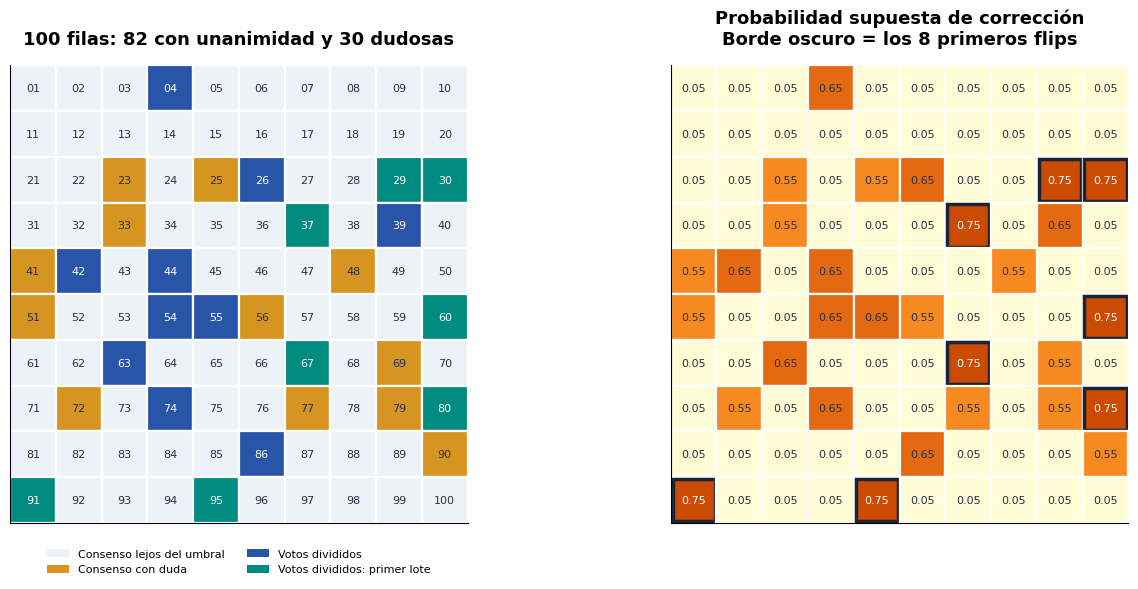

Conjunto,Unanimidad,Filas,Porcentaje,Alcance
Maqueta de 100 celdas,82,100,"82,00%",7 modelos ilustrativos
Test real,29375,30000,"97,92%","7 semillas de una familia, no todas las arquitecturas"


In [4]:
from matplotlib.patches import Rectangle, Patch
from matplotlib.colors import Normalize

rng100 = np.random.default_rng(20261018)
tipo100 = np.array(["consenso_claro"]*70 + ["consenso_dudoso"]*12 +
                   ["discrepancia_dudosa"]*10 + ["discrepancia_fuerte"]*8)
tipo100 = tipo100[rng100.permutation(100)]
propiedades100 = {
    "consenso_claro": (7, .05, PALETA["claro"], "Consenso lejos del umbral"),
    "consenso_dudoso": (7, .55, PALETA["ambar"], "Consenso con duda"),
    "discrepancia_dudosa": (4, .65, PALETA["azul"], "Votos divididos"),
    "discrepancia_fuerte": (5, .75, PALETA["verde"], "Votos divididos: primer lote"),
}
toy100 = pd.DataFrame({"celda":np.arange(1,101), "grupo":tipo100})
toy100["votos_iguales"]=[propiedades100[g][0] for g in tipo100]
toy100["q_supuesta"]=[propiedades100[g][1] for g in tipo100]
toy100["dudosa"]=toy100.grupo.ne("consenso_claro")
toy100["primer_lote"]=toy100.grupo.eq("discrepancia_fuerte")

fig,axes=plt.subplots(1,2,figsize=(13.5,6))
for j,row in toy100.iterrows():
    x,y=j%10,j//10
    color=propiedades100[row.grupo][2]
    axes[0].add_patch(Rectangle((x,y),1,1,facecolor=color,edgecolor="white",linewidth=1.6))
    axes[0].text(x+.5,y+.5,f"{row.celda:02d}",ha="center",va="center",fontsize=8,
                 color="white" if row.grupo in ("discrepancia_dudosa","discrepancia_fuerte") else "#263144")
    axes[1].add_patch(Rectangle((x,y),1,1,facecolor=plt.cm.YlOrBr(row.q_supuesta),
                                 edgecolor="white",linewidth=1.6))
    axes[1].text(x+.5,y+.5,f"{row.q_supuesta:.2f}",ha="center",va="center",fontsize=8,
                 color="white" if row.q_supuesta>.68 else "#263144")
    if row.primer_lote:
        axes[1].add_patch(Rectangle((x+.04,y+.04),.92,.92,fill=False,
                                    edgecolor="#1B2435",linewidth=2.5))
for ax in axes:
    ax.set(xlim=(0,10),ylim=(10,0),aspect="equal")
    ax.set_xticks(np.arange(11));ax.set_yticks(np.arange(11))
    ax.tick_params(length=0,labelbottom=False,labelleft=False)
    ax.grid(False)
axes[0].set_title("100 filas: 82 con unanimidad y 30 dudosas",pad=15)
axes[1].set_title("Probabilidad supuesta de corrección\nBorde oscuro = los 8 primeros flips",pad=15)
axes[0].legend(handles=[Patch(facecolor=v[2],label=v[3]) for v in propiedades100.values()],
               loc="upper center",bbox_to_anchor=(.5,-.035),ncol=2,fontsize=8)
fig.tight_layout();plt.show()
assert len(toy100)==100 and toy100.dudosa.sum()==30
assert (toy100.votos_iguales==7).sum()==82 and toy100.primer_lote.sum()==8

votos_discrepan_real=sum(r["rows"] for r in D["doubt_overlap"] if r["seed_disagreement"])
unanimidad_real=C["test_total"]-votos_discrepan_real
tabla(pd.DataFrame([
    ("Maqueta de 100 celdas",82,100,"82,00%","7 modelos ilustrativos"),
    ("Test real",unanimidad_real,C["test_total"],pct(unanimidad_real/C["test_total"],2),
     "7 semillas de una familia, no todas las arquitecturas"),
],columns=["Conjunto","Unanimidad","Filas","Porcentaje","Alcance"]))
idea("97,92% de unanimidad entre semillas reales no implica 97,92% de aciertos. El desacuerdo es una señal; la unanimidad tampoco es una prueba de verdad.")

### Una celda pintada no dice si la etiqueta es correcta

Elegimos las ocho celdas con borde oscuro para una primera prueba. En la maqueta asumimos que cada alternativa de ese grupo tiene probabilidad $q=0{,}75$ de ser correcta. También usamos $\pi=0{,}70$ como probabilidad aproximada de pertenecer a la parte pública. Son **supuestos de planificación**: ni $q$ ni la membresía pública de cada fila están observados.

¿Qué significa el cambio de score? Para cada una de las ocho filas, $Z_i=+1$ si es pública y corregimos, $Z_i=-1$ si es pública y empeoramos, y $Z_i=0$ si es oculta. El experimento sólo devuelve $D=\sum_{i=1}^8Z_i$. Si viéramos **$D=+4$**, las tres filas de abajo serían configuraciones posibles del *mismo resultado*.

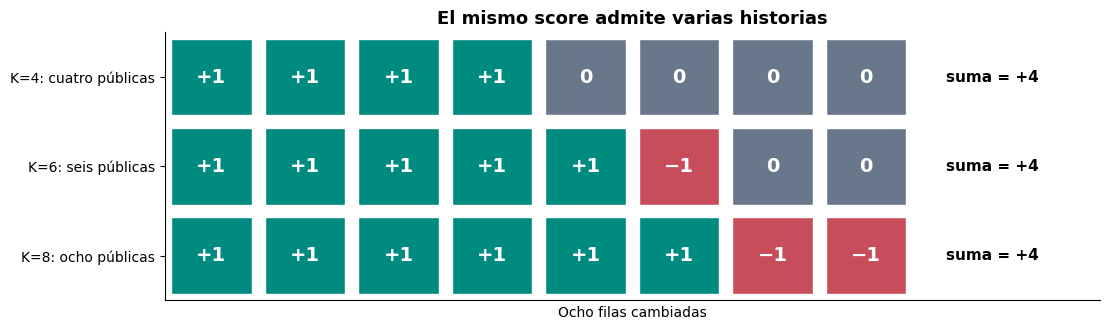

Nivel,Resultado,Interpretación
Observado en el ejemplo,+4 aciertos netos en ocho cambios,Suma: información exacta del lote
Inferido sin probabilidades,"K ∈ {4, 6, 8}","Tres posibilidades, ninguna asigna las ocho etiquetas"
"Posterior si π=0,70 y q ~ Beta(1,1)","77,6%",Promedio para una cohorte hipotéticamente intercambiable
"Probabilidad de q > 0,5 con esos supuestos","94,6%","Confianza del modelo estadístico, no certeza por fila"


In [5]:
escenarios100=[
    ("K=4: cuatro públicas",4,4,0,4),
    ("K=6: seis públicas",6,5,1,2),
    ("K=8: ocho públicas",8,6,2,0),
]
fig,ax=plt.subplots(figsize=(11.2,3.4))
for r,(titulo,k,s,mal,ocultos) in enumerate(escenarios100):
    for col,valor in enumerate([1]*s+[-1]*mal+[0]*ocultos):
        color={1:PALETA["verde"],-1:PALETA["rojo"],0:PALETA["gris"]}[valor]
        ax.add_patch(Rectangle((col+.07,r+.07),.86,.86,facecolor=color,edgecolor="white"))
        ax.text(col+.5,r+.5,{1:"+1",-1:"−1",0:"0"}[valor],ha="center",va="center",
                color="white",fontsize=14,fontweight="bold")
    ax.text(8.35,r+.5,"suma = +4",ha="left",va="center",fontsize=11,fontweight="bold")
ax.set(xlim=(0,10),ylim=(3,0),yticks=np.arange(3)+.5,yticklabels=[s[0] for s in escenarios100],
       title="El mismo score admite varias historias",xlabel="Ocho filas cambiadas")
ax.set_xticks([]);ax.grid(False)
fig.tight_layout();plt.show()

post100=cohort_posterior(8,4,pi=.7,a=1,b=1)
tabla(pd.DataFrame([
    ("Observado en el ejemplo", "+4 aciertos netos en ocho cambios", "Suma: información exacta del lote"),
    ("Inferido sin probabilidades", "K ∈ {4, 6, 8}", "Tres posibilidades, ninguna asigna las ocho etiquetas"),
    ("Posterior si π=0,70 y q ~ Beta(1,1)",pct(post100["theta_mean"],1),
     "Promedio para una cohorte hipotéticamente intercambiable"),
    ("Probabilidad de q > 0,5 con esos supuestos",pct(post100["theta_probability_gt_half"],1),
     "Confianza del modelo estadístico, no certeza por fila"),
],columns=["Nivel","Resultado","Interpretación"]))
idea("El score no revela ocho etiquetas. La posterior cambia si cambiamos la probabilidad pública π, la prior o la suposición de que los casos del lote son comparables.")

### Una segunda prueba puede convertir una suma en una certeza parcial

Conservamos **el mismo control** y probamos sólo las cuatro primeras filas del grupo anterior. Supongamos que la ganancia medida ahora es $D_{1:4}=+4$. Como cada $Z_i\leq 1$, para sumar cuatro en cuatro filas necesariamente $Z_1=Z_2=Z_3=Z_4=+1$: estas cuatro alternativas son correctas **y públicas**. Por sustracción, las otras cuatro tienen $D_{5:8}=+4-(+4)=0$, pero sus etiquetas individuales todavía son inciertas.

No tuvimos que inventar sus etiquetas ni confiar en las probabilidades para demostrar las cuatro primeras. En una prueba real, esto exige que ambos scores compartan un control auditado y que la conversión del score publicado a aciertos enteros sea inequívoca. Una suma cero **no** significa cuatro errores: pueden compensarse aciertos, errores y filas privadas.

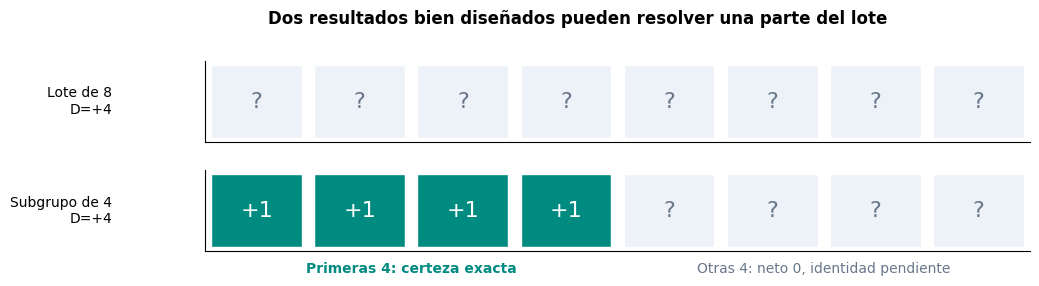

In [6]:
fig,axes=plt.subplots(2,1,figsize=(11.3,3.4),sharex=True)
for r,ax in enumerate(axes):
    for col in range(8):
        seguro=(r==1 and col<4)
        ax.add_patch(Rectangle((col+.06,.05),.88,.9,
                               facecolor=PALETA["verde"] if seguro else PALETA["claro"],
                               edgecolor="white"))
        ax.text(col+.5,.5,"+1" if seguro else "?",ha="center",va="center",
                color="white" if seguro else PALETA["gris"],fontsize=16)
    ax.set(xlim=(0,8),ylim=(0,1),yticks=[],xticks=[])
    ax.grid(False)
    ax.set_ylabel("Lote de 8\nD=+4" if r==0 else "Subgrupo de 4\nD=+4",rotation=0,
                  ha="right",va="center",labelpad=67)
axes[1].annotate("Primeras 4: certeza exacta",xy=(2,.02),xytext=(2,-.27),
                 ha="center",color=PALETA["verde"],fontweight="bold",annotation_clip=False)
axes[1].annotate("Otras 4: neto 0, identidad pendiente",xy=(6,.02),xytext=(6,-.27),
                 ha="center",color=PALETA["gris"],annotation_clip=False)
fig.suptitle("Dos resultados bien diseñados pueden resolver una parte del lote",fontweight="bold")
fig.subplots_adjust(left=.17,bottom=.27,top=.83,hspace=.35)
plt.show()

### ¿Cuántas pruebas hacen falta? Depende de la pregunta

**1. Para tocar cada fila una vez:** si hay $U$ casos y cambiamos como máximo $b$ *casos nuevos y disjuntos* por prueba, hacen falta $n_{\rm cobertura}=\lceil U/b\rceil$. En la maqueta, $\lceil30/8\rceil=4$. En el test, $\lceil2.531/64\rceil=40$ si mantuviéramos 64 casos nuevos en cada envío. Con el **diseño provisional de lotes más grandes**, el primer lote de 64 más otros 14 de tamaños 176–178 cubriría los 2.531 en **15** pruebas, si se conserva el diseño al llegar cada score.

**2. Para favorecer una mejora de score bajo un supuesto:** si las alternativas de un grupo tienen una probabilidad común $q$ de ser correctas y cada fila cae en público con probabilidad $\pi$, entonces, *aproximando filas independientes*,

$$P(Z=+1)=\pi q,\quad P(Z=-1)=\pi(1-q),\quad P(Z=0)=1-\pi;$$
$$E[D_b]=b\pi(2q-1),\qquad
\operatorname{Var}(D_b)=b\big[\pi-\pi^2(2q-1)^2\big].$$

Con $q=0{,}65$ y $\pi=0{,}70$, calculamos exactamente la distribución predictiva de $D_b$ bajo ese **modelo de trabajo** y buscamos el primer tamaño con $P(D_b>0)\geq90\%$. Ese cálculo no equivale a 90% de confianza sobre las etiquetas ni promete una mejora real.

**3. Para identificar *todas* las etiquetas sin usar modelos:** hay que responder otra pregunta. Cada uno de $U$ casos puede contribuir $-1$, $0$ o $+1$, y un lote de $b$ devuelve a lo sumo $2b+1$ sumas posibles. Por conteo de posibilidades, una condición necesaria idealizada para distinguir cualquier configuración sería

$$n_{\rm identificación}\;\geq\;
\left\lceil\frac{U\log_2(3)}{\log_2(2b+1)}\right\rceil.$$

Es un **límite inferior de información**, no una receta suficiente. La precisión del score, los solapamientos y los controles pueden exigir más pruebas. Por eso, con 75 resultados agregados usamos probabilidades de modelos y estructura para orientar decisiones; no prometemos descubrir las 2.531 etiquetas exactas.

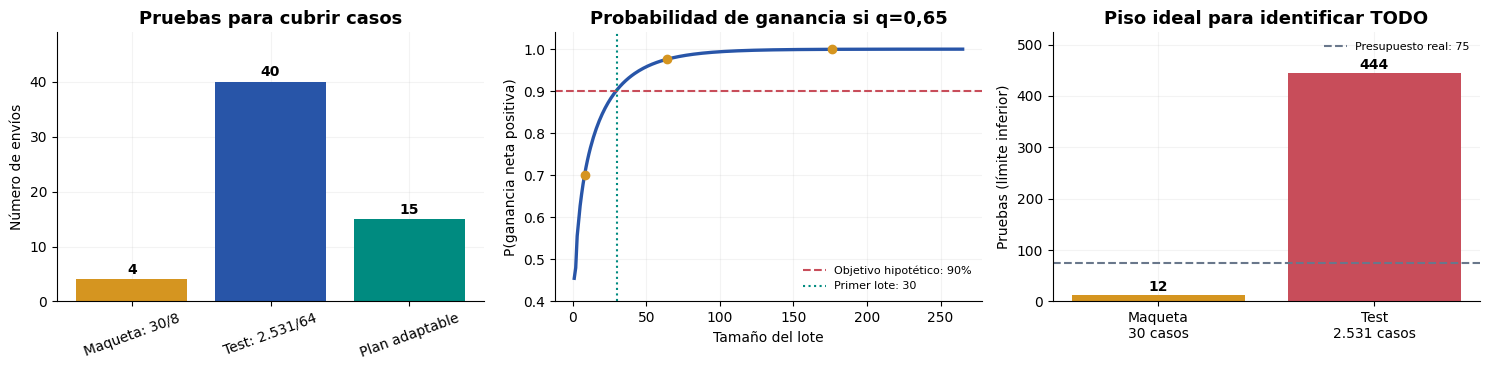

Objetivo,Mínimo o plan,Qué concluye realmente
"Cobertura de 30 casos, ocho nuevos por prueba",4,Garantiza visitar cada caso una vez
"Cobertura de 2.531, 64 nuevos por prueba",40,No identifica etiquetas por sí sola
Cobertura con lotes previstos 64 + 14×(176–178),15,Diseño revisable tras cada score
"P(D>0) ≥ 90% si q=0,65 y π=0,70",30,"Predicción condicional al supuesto, NO confianza empírica"
"Piso ideal para todas las etiquetas, lotes ≤265",444,"Necessary, nunca suficiente: presupuesto de 75 insuficiente para esta meta"


In [7]:
from math import ceil,log2

# Convolución exacta dentro del modelo hipotético; no utiliza etiquetas del test.
q_hipotesis,pi_hipotesis=.65,.70
pmf=np.ones(1)
curva=[]
for b in range(1,266):
    pmf=np.convolve(pmf,[pi_hipotesis*(1-q_hipotesis),1-pi_hipotesis,pi_hipotesis*q_hipotesis])
    curva.append(float(pmf[b+1:].sum()))
minimo_90=next(b for b,p in enumerate(curva,1) if p>=.90)
max_preview=max(s["proposed_flips"] for s in D["plan_schedule"])
filas_15=[s["proposed_flips"] for s in D["plan_schedule"][:15]]
assert sum(filas_15)==C["ambiguous_unverified"]

fig,axes=plt.subplots(1,3,figsize=(15,3.8))
axes[0].bar(["Maqueta: 30/8","Test: 2.531/64","Plan adaptable"],[4,40,15],
            color=[PALETA["ambar"],PALETA["azul"],PALETA["verde"]])
for i,v in enumerate([4,40,15]):axes[0].text(i,v+1,str(v),ha="center",fontweight="bold")
axes[0].set(title="Pruebas para cubrir casos",ylabel="Número de envíos",ylim=(0,49))
axes[0].tick_params(axis="x",labelrotation=20)
axes[1].plot(np.arange(1,266),curva,color=PALETA["azul"],lw=2.4)
axes[1].axhline(.90,color=PALETA["rojo"],ls="--",label="Objetivo hipotético: 90%")
axes[1].axvline(minimo_90,color=PALETA["verde"],ls=":",label=f"Primer lote: {minimo_90}")
axes[1].scatter([8,64,176],[curva[7],curva[63],curva[175]],color=PALETA["ambar"],zorder=3)
axes[1].set(title="Probabilidad de ganancia si q=0,65",xlabel="Tamaño del lote",
            ylabel="P(ganancia neta positiva)",ylim=(.4,1.04))
axes[1].legend(fontsize=8,loc="lower right")
limite_toy=ceil(30*log2(3)/log2(2*8+1))
limite_real=ceil(C["ambiguous_unverified"]*log2(3)/log2(2*max_preview+1))
axes[2].bar(["Maqueta\n30 casos","Test\n2.531 casos"],[limite_toy,limite_real],
            color=[PALETA["ambar"],PALETA["rojo"]])
axes[2].axhline(75,color=PALETA["gris"],ls="--",label="Presupuesto real: 75")
for i,v in enumerate([limite_toy,limite_real]):axes[2].text(i,v+8,str(v),ha="center",fontweight="bold")
axes[2].set(title="Piso ideal para identificar TODO",ylabel="Pruebas (límite inferior)",
            ylim=(0,limite_real*1.18))
axes[2].legend(fontsize=8)
fig.tight_layout();plt.show()

tabla(pd.DataFrame([
    ("Cobertura de 30 casos, ocho nuevos por prueba",ceil(30/8),"Garantiza visitar cada caso una vez"),
    ("Cobertura de 2.531, 64 nuevos por prueba",ceil(2531/64),"No identifica etiquetas por sí sola"),
    ("Cobertura con lotes previstos 64 + 14×(176–178)",15,"Diseño revisable tras cada score"),
    ("P(D>0) ≥ 90% si q=0,65 y π=0,70",minimo_90,"Predicción condicional al supuesto, NO confianza empírica"),
    ("Piso ideal para todas las etiquetas, lotes ≤265",limite_real,
     "Necessary, nunca suficiente: presupuesto de 75 insuficiente para esta meta"),
],columns=["Objetivo","Mínimo o plan","Qué concluye realmente"]))
idea("Cobertura, ganancia probable e identificación individual son tres objetivos distintos. Lotes grandes dan alcance; lotes cruzados o subdivididos dan resolución. La estrategia alterna ambos.")
assert (unanimidad_real,votos_discrepan_real)==(29375,625)
assert minimo_90==30 and limite_toy==12 and limite_real==444

## 2. Qué pasó en las submissions

El registro incluye **pruebas buenas, malas y neutrales**. Una caída aporta información sobre una hipótesis aunque ese archivo no se convierta en el nuevo mejor candidato.

El eje horizontal representa **el orden del registro**, no horas transcurridas. La línea de mejor score conserva el máximo observado hasta ese punto.

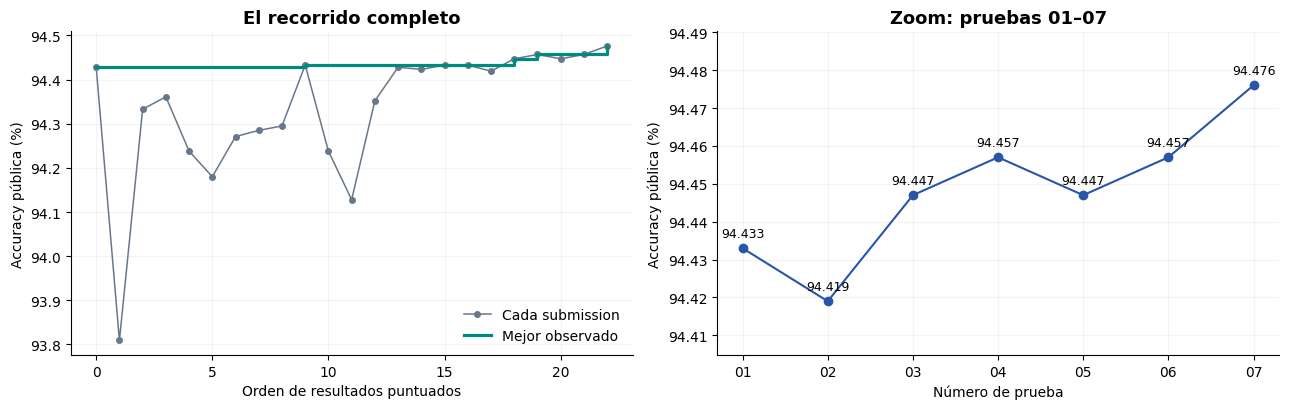

In [8]:
x = np.arange(len(observadas))
s = observadas.public_score.to_numpy(float)
fig, axes = plt.subplots(1,2,figsize=(13,4.2))
axes[0].plot(x,100*s,"o-",color=PALETA["gris"],label="Cada submission",lw=1.1,ms=4)
axes[0].step(x,100*np.maximum.accumulate(s),where="post",color=PALETA["verde"],lw=2.3,label="Mejor observado")
axes[0].set(title="El recorrido completo",xlabel="Orden de resultados puntuados",ylabel="Accuracy pública (%)")
axes[0].legend()
recent = observadas[observadas.name.str.match(r"submission_0[1-7]_")].copy()
positions = np.arange(len(recent))
axes[1].plot(positions,100*recent.public_score,"o-",color=PALETA["azul"])
for j,row in enumerate(recent.itertuples()):
    axes[1].annotate(f"{100*row.public_score:.3f}",(j,100*row.public_score),
                     xytext=(0,8),textcoords="offset points",ha="center",fontsize=9)
axes[1].set_xticks(positions, [name.split("_")[1] for name in recent.name])
axes[1].set(title="Zoom: pruebas 01–07",xlabel="Número de prueba",ylabel="Accuracy pública (%)")
axes[1].margins(y=.25)
fig.tight_layout();plt.show()
idea("Una mejora de pocos aciertos puede ser útil. Para interpretarla primero reconstruimos el control y los IDs modificados.")

In [9]:
registro = H[["name","public_score","status","n_flips_vs_verified_control"]].copy()
registro.columns=["Archivo","Score público","Estado","Cambios vs control verificado"]
tabla(registro, formatter={"Score público":lambda x:"Pendiente" if pd.isna(x) else pct(x)})
display(Markdown("**Pendientes:** " + ", ".join(pendientes.name.tolist()) + "."))

Archivo,Score público,Estado,Cambios vs control verificado
submission_best_public_94428.csv,"94,428%",observed,1
submission_title_char_blend_challenger.csv,"93,809%",observed,744
submission_low_consensus_plus_verified.csv,"94,333%",observed,109
submission_consensus_3of4.csv,"94,361%",observed,57
submission_consensus_4of4_a.csv,"94,238%",observed,289
submission_consensus_4of4_b.csv,"94,180%",observed,288
submission_bayes_conf_low.csv,"94,271%",observed,192
submission_bayes_conf_mid.csv,"94,285%",observed,192
submission_bayes_conf_high.csv,"94,295%",observed,192
submission_bayes_verified_only.csv,"94,433%",observed,0


**Pendientes:** submission_probe_fresh_high_posterior_5_v2.csv, submission_08_consenso_nuevo_8.csv, submission_09_audita_ganador_3.csv, submission_10_lote64_ganancias_acumuladas.csv.

## 3. Cómo se traduce un flip a un cambio de score

Pensemos en una fila cuya etiqueta real es used:
- Si el control predice new y lo cambiamos a used, ganamos un acierto.
- Si el control ya predecía used y lo cambiamos a new, perdemos un acierto.
- Si la fila no pertenece a la porción pública, el score público no cambia.

Para cada flip definimos una variable latente:

$$
Z_i=
\begin{cases}
+1 & \text{fila pública y alternativa correcta},\\
-1 & \text{fila pública y alternativa incorrecta},\\
0 & \text{fila oculta}.
\end{cases}
$$

En un lote de flips $B$:

$$D_B=\sum_{i\in B}Z_i,\qquad
\Delta\mathrm{accuracy}=\frac{D_B}{N_{\mathrm{público}}}.$$

**D es la ganancia neta, no la cantidad de flips correctos.**

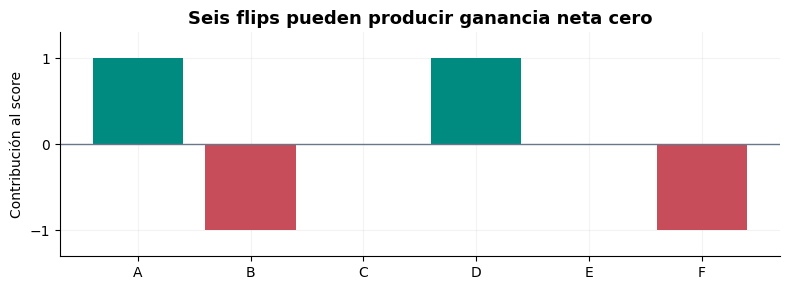

Caso,Porción,Control,Alternativa,Etiqueta real,Z
A,Pública,new,used,used,1
B,Pública,used,new,used,-1
C,Oculta,new,used,used,0
D,Pública,new,used,used,1
E,Oculta,used,new,used,0
F,Pública,new,used,new,-1


In [10]:
# Ejemplo inventado para ver el mecanismo; no son etiquetas del test real.
toy = pd.DataFrame({
    "Caso":["A","B","C","D","E","F"],
    "Porción":["Pública","Pública","Oculta","Pública","Oculta","Pública"],
    "Control":["new","used","new","new","used","new"],
    "Alternativa":["used","new","used","used","new","used"],
    "Etiqueta real":["used","used","used","used","used","new"],
})
toy["Z"] = [
    0 if r["Porción"]=="Oculta" else (1 if r["Alternativa"]==r["Etiqueta real"] else -1)
    for _,r in toy.iterrows()
]
fig,ax=plt.subplots(figsize=(8,3))
ax.bar(toy.Caso,toy.Z,color=[PALETA["verde"] if z>0 else PALETA["rojo"] if z<0 else PALETA["gris"] for z in toy.Z])
ax.axhline(0,color=PALETA["gris"],lw=1)
ax.set(ylim=(-1.3,1.3),yticks=[-1,0,1],ylabel="Contribución al score",title="Seis flips pueden producir ganancia neta cero")
fig.tight_layout();plt.show()
tabla(toy)
idea(f"En este ejemplo conocemos la verdad para enseñar el mecanismo. En la competencia sólo observamos la suma: D = {toy.Z.sum():+d}.")

### Primer cuidado: un resultado neto no identifica las filas

En la prueba 07 se cambiaron ocho casos nuevos y el aporte público neto fue $D=+4$.

Sea $K$ la cantidad de esos ocho casos que efectivamente están en público y $S$ la cantidad de alternativas correctas entre ellos. Entonces:

$$D=S-(K-S)=2S-K,\qquad S=\frac{K+D}{2}.$$

No vemos ni $K$ ni las identidades de las filas que forman $S$. Podemos enumerar configuraciones compatibles.

In [11]:
compatibles=[]
for k in range(9):
    if (k+4)%2==0 and 0 <= (k+4)//2 <= k:
        correctos=(k+4)//2
        compatibles.append((k,correctos,k-correctos,8-k,2*correctos-k))
tabla(pd.DataFrame(compatibles,columns=[
    "K públicas","S alternativas correctas públicas","Alternativas incorrectas públicas",
    "Filas ocultas","D neto"]))
idea("Las tres configuraciones explican +4. Además, ninguna revela por sí sola cuáles son las etiquetas de las filas ocultas.")

K públicas,S alternativas correctas públicas,Alternativas incorrectas públicas,Filas ocultas,D neto
4,4,0,4,4
6,5,1,2,4
8,6,2,0,4


## 4. Del score mostrado a un número entero de aciertos

La plataforma muestra cinco decimales de accuracy, pero el numerador verdadero es entero. Eso restringe el tamaño público y la interpretación de los cambios.

Si el score se trunca:
$$
\hat s\leq\frac{c}{N}<\hat s+10^{-5}.
$$

Si se redondea al más cercano:
$$
\hat s-\tfrac12 10^{-5}\leq\frac{c}{N}<\hat s+\tfrac12 10^{-5}.
$$

El historial es compatible con dos hipótesis que conservamos:
**21.000 filas y truncamiento**, o **20.998 filas y redondeo**. Son inferencias, no una confirmación oficial.

In [12]:
denominadores=np.arange(1000,30001)
compatibilidad=[]
for modo in ["truncate","round"]:
    ok=np.ones(len(denominadores),bool)
    for sc in observadas.public_score:
        paso=1e-5
        lo=sc if modo=="truncate" else sc-paso/2
        hi=sc+paso if modo=="truncate" else sc+paso/2
        primero=np.ceil(lo*denominadores-1e-8)
        ultimo_exclusivo=np.ceil(hi*denominadores-1e-8)
        ok &= primero < ultimo_exclusivo
    compatibilidad.extend((int(n),modo) for n in denominadores[ok])
tabla(pd.DataFrame(compatibilidad,columns=["Tamaño público compatible","Visualización"]))
assert (21000,"truncate") in compatibilidad and (20998,"round") in compatibilidad
conversión=[]
for nombre in ["submission_bayes_verified_only.csv","submission_03_probe_red_discrepa_10.csv",
               "submission_06_rescata_consenso_8.csv","submission_07_extiende_estable_8.csv"]:
    row=observadas[observadas.name.eq(nombre)].iloc[0]
    a=score_count_candidates(row.public_score,21000,"truncate")
    b=score_count_candidates(row.public_score,20998,"round")
    assert len(a)==len(b)==1
    conversión.append((nombre,row.public_score,int(a[0]),int(b[0])))
cuentas=pd.DataFrame(conversión,columns=["Archivo","Score","Aciertos N=21.000","Aciertos N=20.998"])
tabla(cuentas,formatter={"Score":pct})

Tamaño público compatible,Visualización
21000,truncate
20998,round


Archivo,Score,Aciertos N=21.000,Aciertos N=20.998
submission_bayes_verified_only.csv,"94,433%",19831,19829
submission_03_probe_red_discrepa_10.csv,"94,447%",19834,19832
submission_06_rescata_consenso_8.csv,"94,457%",19836,19834
submission_07_extiende_estable_8.csv,"94,476%",19840,19838


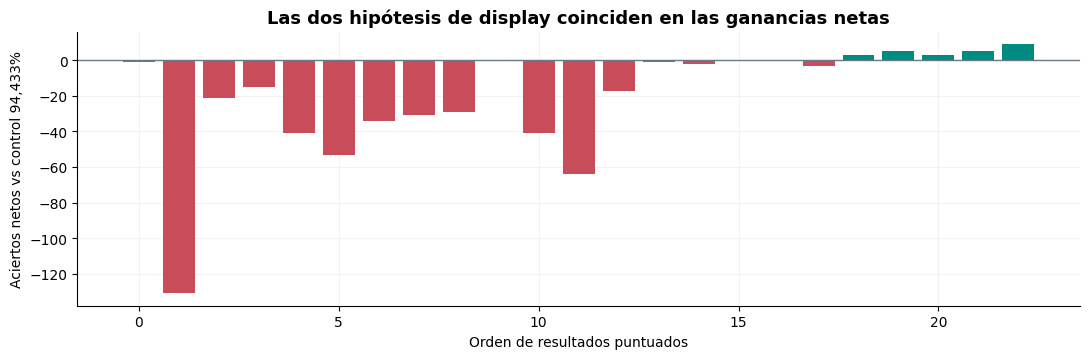

In [13]:
base=observadas[observadas.name.eq("submission_bayes_verified_only.csv")].public_score.iloc[0]
for n,modo in [(21000,"truncate"),(20998,"round")]:
    c0=int(score_count_candidates(base,n,modo)[0])
    observadas[f"delta_{n}"]=[int(score_count_candidates(s,n,modo)[0])-c0 for s in observadas.public_score]
assert np.array_equal(observadas.delta_21000,observadas.delta_20998)
fig,ax=plt.subplots(figsize=(11,3.7))
indices=np.arange(len(observadas));delta=observadas.delta_21000.to_numpy()
ax.bar(indices,delta,color=np.where(delta>=0,PALETA["verde"],PALETA["rojo"]))
ax.axhline(0,color=PALETA["gris"],lw=1)
ax.set(xlabel="Orden de resultados puntuados",ylabel="Aciertos netos vs control 94,433%",
       title="Las dos hipótesis de display coinciden en las ganancias netas")
fig.tight_layout();plt.show()

## 5. Cuántos casos dudosos tenemos

Una fila entra al universo de revisión si se cumple al menos uno de estos criterios operativos:

1. El score probabilístico de la alternativa está entre **0,20 y 0,80**.
2. Entre **1 y 6 de las 7 semillas** apoyan la alternativa: hay desacuerdo.

No estamos afirmando que todas esas filas estén mal. Estamos definiendo dónde resulta útil investigar. Tampoco son siete opiniones independientes: las semillas comparten datos y arquitectura.

La unión da **2.532 filas**. Una ya tenía etiqueta verificada y se excluye: trabajamos con **2.531 casos dudosos sin verificación individual**.

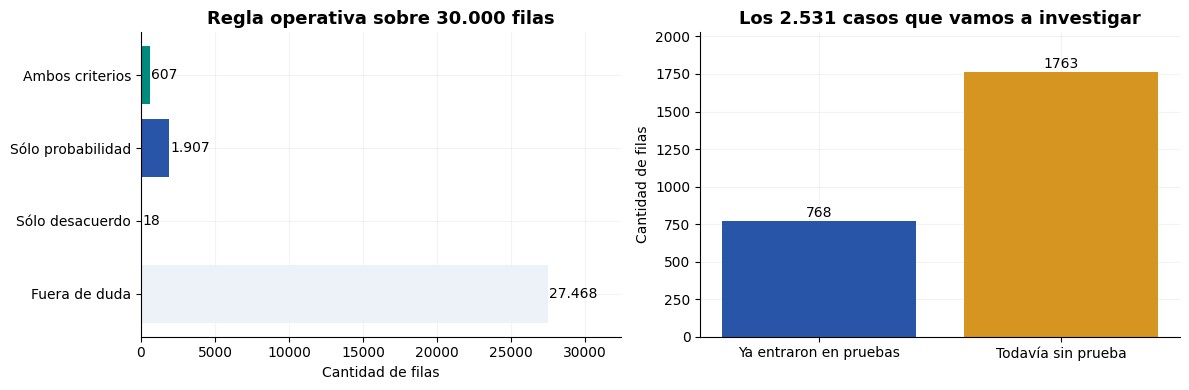

In [14]:
overlap=pd.DataFrame(D["doubt_overlap"])
assert overlap.rows.sum()==30000
union_count=int(overlap.loc[overlap.probability_doubt|overlap.seed_disagreement,"rows"].sum())
assert union_count==C["raw_ambiguous_union"]
fig,axes=plt.subplots(1,2,figsize=(12,4))
etiquetas=["Fuera de duda","Sólo desacuerdo","Sólo probabilidad","Ambos criterios"]
axes[0].barh(etiquetas,overlap.rows,color=[PALETA["claro"],PALETA["ambar"],PALETA["azul"],PALETA["verde"]])
for j,v in enumerate(overlap.rows):axes[0].text(v+90,j,f"{v:,}".replace(",","."),va="center")
axes[0].set(title="Regla operativa sobre 30.000 filas",xlabel="Cantidad de filas")
axes[0].set_xlim(0,overlap.rows.max()*1.18)
axes[1].bar(["Ya entraron en pruebas","Todavía sin prueba"],[C["ambiguous_scored"],C["ambiguous_unscored"]],
             color=[PALETA["azul"],PALETA["ambar"]])
for j,v in enumerate([C["ambiguous_scored"],C["ambiguous_unscored"]]):
    axes[1].text(j,v+30,str(v),ha="center")
axes[1].set(title="Los 2.531 casos que vamos a investigar",ylabel="Cantidad de filas")
axes[1].margins(y=.15)
fig.tight_layout();plt.show()
idea(f"Se probaron {C['unique_tested_ids']} IDs distintos en todo el historial. De ellos, {C['ambiguous_scored']} pertenecen al universo dudoso vigente; otros pertenecen a pruebas históricas que hoy no cumplen esta regla.")

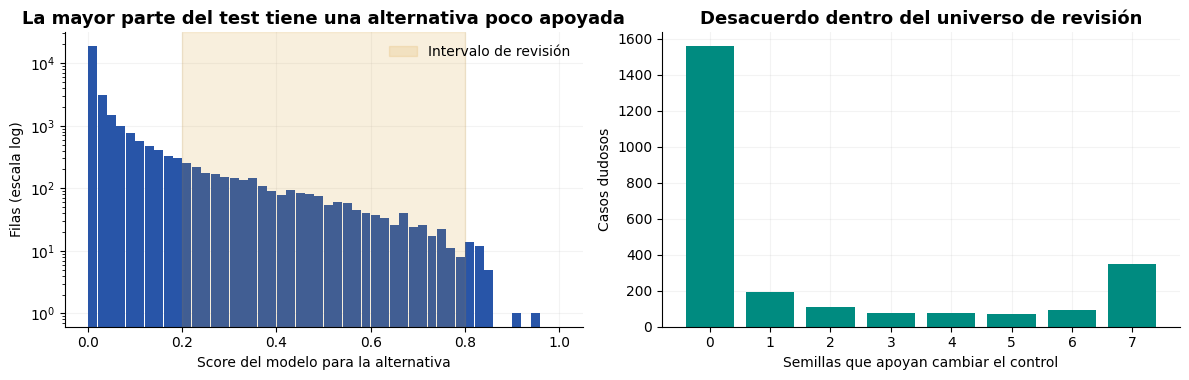

In [15]:
fig,axes=plt.subplots(1,2,figsize=(12,3.9))
hist=D["all_alt_probability_histogram"];edges=np.array(hist["edges"])
axes[0].bar((edges[:-1]+edges[1:])/2,hist["counts"],width=np.diff(edges)*.95,color=PALETA["azul"])
axes[0].axvspan(.2,.8,color=PALETA["ambar"],alpha=.15,label="Intervalo de revisión")
axes[0].set(yscale="log",xlabel="Score del modelo para la alternativa",ylabel="Filas (escala log)",
            title="La mayor parte del test tiene una alternativa poco apoyada")
axes[0].legend()
v=casos.groupby("full70k_seed_votes_alternative_out_of_7").size().reindex(range(8),fill_value=0)
axes[1].bar(v.index,v.values,color=PALETA["verde"])
axes[1].set(xticks=range(8),xlabel="Semillas que apoyan cambiar el control",ylabel="Casos dudosos",
            title="Desacuerdo dentro del universo de revisión")
fig.tight_layout();plt.show()

### Del universo grande al lote concreto

Para la submission 10 no se eligieron 64 casos al azar entre los 2.531. Se parte de un patrón que produjo resultados positivos:

- La red anterior **discrepa** con el cambio.
- Al menos cinco de las siete semillas de la base fuerte lo apoyan.
- El modelo de referencia da a la alternativa un score de al menos 0,45.
- Los nuevos modelos contribuyen al ordenamiento y se diversifica por grupo de publicación.

Ese filtro dejó **74 candidatos**; se eligieron 64. Esto aporta una hipótesis de transferencia concreta: comprobar si el patrón sigue funcionando al ampliar el lote.

In [16]:
hoy=pd.DataFrame(D["submission10_cases"])
ejemplos=hoy[["ID","batch_block","title","old_condition","new_condition",
               "old_reference_probability_alternative","full70k_seed_votes_alternative_out_of_7"]].head(8).copy()
ejemplos.columns=["ID","Bloque","Título","Control","Alternativa","Score alternativo del modelo","Votos de 7"]
tabla(ejemplos,formatter={"Score alternativo del modelo":"{:.3f}"})
idea("Son publicaciones reales y predicciones propuestas. La tabla no contiene sus etiquetas verdaderas.")

ID,Bloque,Título,Control,Alternativa,Score alternativo del modelo,Votos de 7
161,A,campera - forever 21,used,new,0.822,6
3822,A,mono ski - obermeyer,used,new,0.736,7
29535,A,funda estuche samsung galaxy s3 i9300 flip cover original,used,new,0.726,7
460,A,vestido - forever 21,used,new,0.818,5
27763,A,curriculum abierto y propuestas didacticas en educacion,used,new,0.821,6
5015,A,antigua propaganda - jabon de tocador campanita,used,new,0.650,7
6996,A,chopera de 1 lts - con disenos de ciervos - germany !!!,used,new,0.713,7
14035,A,iphone 6,used,new,0.753,5


## 6. Cómo estimamos la confianza: Bayes paso a paso

Queremos estimar qué proporción de alternativas de una cohorte comparable es correcta. La llamamos $\theta$.

1. **Antes de la prueba:** usamos un prior. $\mathrm{Beta}(1,1)$ es uniforme; también probamos priors más centrados en 0,5.
2. **Dato observado:** el lote tiene $n$ flips y produjo una ganancia pública neta $D$.
3. **Lo que falta:** cuántas filas del lote son públicas ($K$) y cuáles de ellas fueron correctas.
4. **Actualización:** consideramos todas las configuraciones compatibles y ponderamos su probabilidad.

La fracción pública $\pi=0,7$ es un supuesto compatible con una de las hipótesis de tamaño. No observamos la pertenencia por ID.

**Ejemplo real que vamos a resolver:** ocho flips de la 07, $D=+4$.

In [17]:
post07=cohort_posterior(n=8,delta=4,pi=.7,a=1,b=1)
config=pd.DataFrame({
    "K públicas":post07["k"],
    "S alternativas correctas":post07["successes"],
    "Peso posterior":post07["weights"],
    "Media de theta si K fuera éste":post07["alpha_components"]/(post07["alpha_components"]+post07["beta_components"]),
})
tabla(config,formatter={"Peso posterior":"{:.1%}","Media de theta si K fuera éste":"{:.1%}"})
resumen07=pd.DataFrame([
    ("Tasa de acierto de la población comparable, E[theta]",post07["theta_mean"]),
    ("Acierto esperado en estas ocho filas concretas",post07["finite_cohort_accuracy_mean"]),
    ("Probabilidad posterior de theta > 0,5",post07["theta_probability_gt_half"]),
],columns=["Cantidad estimada","Valor"])
tabla(resumen07,formatter={"Valor":"{:.1%}"})
idea("La tasa de una población comparable y la accuracy de estas ocho filas concretas son cantidades distintas. No debemos usar sus intervalos como si fueran intercambiables.")

K públicas,S alternativas correctas,Peso posterior,Media de theta si K fuera éste
4,4,35.8%,83.3%
6,5,55.7%,75.0%
8,6,8.4%,70.0%


Cantidad estimada,Valor
"Tasa de acierto de la población comparable, E[theta]",77.6%
Acierto esperado en estas ocho filas concretas,84.5%
"Probabilidad posterior de theta > 0,5",94.6%


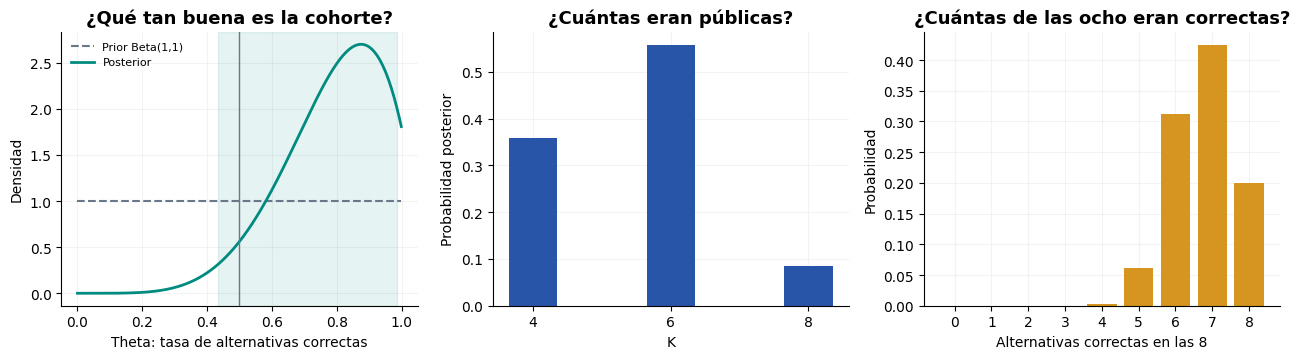

**Intervalo de credibilidad 95% para theta:** 43.3%–98.7%. Se interpreta dentro del modelo de prior, comparabilidad y pertenencia pública.

In [18]:
grid=np.linspace(.001,.999,500)
fig,axes=plt.subplots(1,3,figsize=(13,3.7))
axes[0].plot(grid,np.ones_like(grid),"--",color=PALETA["gris"],label="Prior Beta(1,1)")
axes[0].plot(grid,theta_density(post07,grid),color=PALETA["verde"],lw=2,label="Posterior")
axes[0].axvspan(*post07["theta_ci95"],color=PALETA["verde"],alpha=.1)
axes[0].axvline(.5,color=PALETA["gris"],lw=1)
axes[0].set(title="¿Qué tan buena es la cohorte?",xlabel="Theta: tasa de alternativas correctas",ylabel="Densidad")
axes[0].legend(fontsize=8)
axes[1].bar(post07["k"],post07["weights"],width=.7,color=PALETA["azul"])
axes[1].set(title="¿Cuántas eran públicas?",xlabel="K",ylabel="Probabilidad posterior",xticks=post07["k"])
axes[2].bar(np.arange(9),post07["finite_correct_count_pmf"],color=PALETA["ambar"])
axes[2].set(title="¿Cuántas de las ocho eran correctas?",xlabel="Alternativas correctas en las 8",ylabel="Probabilidad",xticks=range(9))
fig.tight_layout();plt.show()
display(Markdown(
    f"**Intervalo de credibilidad 95% para theta:** "
    f"{post07['theta_ci95'][0]:.1%}–{post07['theta_ci95'][1]:.1%}. "
    "Se interpreta dentro del modelo de prior, comparabilidad y pertenencia pública."
))

### El cálculo que hay detrás

Aproximamos la pertenencia pública de un lote pequeño con:

$$K\sim\mathrm{Binomial}(n,\pi).$$

Dado $K=k$, sólo son compatibles los valores
$s=(k+D)/2$ enteros entre $0$ y $k$. Con prior $\theta\sim\mathrm{Beta}(a,b)$:

$$
w_k=P(K=k\mid D)\ \propto\
{n\choose k}\pi^k(1-\pi)^{n-k}
{k\choose s}\frac{B(a+s,b+k-s)}{B(a,b)}.
$$

Normalizamos los $w_k$ para que sumen 1. El posterior es una mezcla:

$$
p(\theta\mid D)=\sum_k w_k\,
\mathrm{Beta}(\theta;a+s,b+k-s).
$$

Así integramos lo desconocido: **no inventamos un K ni asignamos las S etiquetas a IDs concretos**.

Para estimar cuántas alternativas de las $n$ son correctas, añadimos las filas ocultas mediante una predictiva beta-binomial:

$$
T=s+U,\quad
U\mid K,D\sim\mathrm{BetaBinomial}(n-k,a+s,b+k-s).
$$

Esta última distribución produce el tercer gráfico. La densidad de theta produce el primero.

### Qué depende de los supuestos

Si el conjunto público tuviera exactamente $N_{\mathrm{público}}$ filas elegidas uniformemente del test, la distribución de K sería **hipergeométrica** en lugar de binomial:

$$
P(K=k)=
\frac{\binom{N_{\mathrm{público}}}{k}
\binom{N_{\mathrm{test}}-N_{\mathrm{público}}}{n-k}}
{\binom{N_{\mathrm{test}}}{n}}.
$$

La binomial es una aproximación cómoda para lotes pequeños. Comparamos ambas y también distintos priors: un intervalo estrecho bajo un único supuesto no sería suficiente.

In [19]:
sens=[]
for a,b in [(1,1),(2,2),(5,5)]:
    for pi in [.6,.7,.8]:
        p=cohort_posterior(8,4,pi,a,b)
        sens.append({"Prior":f"Beta({a},{b})","Pi":pi,"Modelo máscara":"Binomial",
                     "Media theta":p["theta_mean"],"Inferior95":p["theta_ci95"][0],
                     "Superior95":p["theta_ci95"][1]})
hyp=cohort_posterior(8,4,.7,1,1,public_total=21000)
sens.append({"Prior":"Beta(1,1)","Pi":.7,"Modelo máscara":"Hipergeométrica",
             "Media theta":hyp["theta_mean"],"Inferior95":hyp["theta_ci95"][0],
             "Superior95":hyp["theta_ci95"][1]})
sens=pd.DataFrame(sens)
tabla(sens,formatter={"Pi":"{:.0%}","Media theta":"{:.1%}","Inferior95":"{:.1%}","Superior95":"{:.1%}"})
idea("Con ocho casos, la incertidumbre del prior y de la comparabilidad importa mucho más que la pequeña corrección binomial/hipergeométrica. El intervalo es de credibilidad bayesiana, no un intervalo frecuentista ni una prueba de significación.")

Prior,Pi,Modelo máscara,Media theta,Inferior95,Superior95
"Beta(1,1)",60%,Binomial,79.8%,44.7%,99.2%
"Beta(1,1)",70%,Binomial,77.6%,43.3%,98.7%
"Beta(1,1)",80%,Binomial,74.8%,41.9%,97.4%
"Beta(2,2)",60%,Binomial,72.4%,40.9%,95.1%
"Beta(2,2)",70%,Binomial,71.1%,40.4%,94.1%
"Beta(2,2)",80%,Binomial,69.5%,39.8%,92.6%
"Beta(5,5)",60%,Binomial,63.2%,38.5%,84.9%
"Beta(5,5)",70%,Binomial,62.7%,38.4%,84.2%
"Beta(5,5)",80%,Binomial,62.1%,38.4%,83.3%
"Beta(1,1)",70%,Hipergeométrica,77.6%,43.3%,98.7%


## 7. Caso real: separar para después combinar

Estas pruebas responden preguntas diferentes:

- **03:** diez flips donde la red anterior discrepaba; resultado neto +3.
- **05:** conservó cinco de esos diez y empató el score de 03. Por diferencia, los cinco retirados aportaban 0 neto; los cinco conservados explican +3.
- **04:** añadió ocho casos nuevos a 03 y aportó +2.
- **07:** partió del control compacto y añadió otros ocho; aportó +4.
- **06:** probó ocho casos dentro del grupo de veinte que había empatado. Esa parte aporta +2; los doce restantes aportan −2.

Las identidades entre conjuntos permiten reutilizar las ganancias compatibles sin volver a gastar una submission en cada combinación intermedia.

In [20]:
def fila(nombre):
    return H[H.name.eq(nombre)].iloc[0]
def conjunto(nombre):
    return set(fila(nombre).flips_vs_verified_control)
def neto(nombre,N=21000,modo="truncate"):
    score=fila(nombre).public_score
    control=fila("submission_bayes_verified_only.csv").public_score
    return int(score_count_candidates(score,N,modo)[0])-int(score_count_candidates(control,N,modo)[0])

s03=conjunto("submission_03_probe_red_discrepa_10.csv")
s04=conjunto("submission_04_amplia_discrepancia_8.csv")
s05=conjunto("submission_05_depura_ganador_5.csv")
s06=conjunto("submission_06_rescata_consenso_8.csv")
s07=conjunto("submission_07_extiende_estable_8.csv")
s01=conjunto("submission_01_consenso_corregido_20.csv")
retirados=s03-s05
frescos04=s04-s03
rescatados06=s06-s03
compacto=s04-retirados
frescos07=s07-compacto
assert s05<=s03 and len(retirados)==5 and len(frescos04)==len(rescatados06)==len(frescos07)==8
assert rescatados06<=s01 and not (s07 & rescatados06)
aislados=pd.DataFrame([
    ("Cinco conservados por 05",5,neto("submission_05_depura_ganador_5.csv")),
    ("Cinco retirados de 03",5,neto("submission_03_probe_red_discrepa_10.csv")-neto("submission_05_depura_ganador_5.csv")),
    ("Ocho nuevos de 04",8,neto("submission_04_amplia_discrepancia_8.csv")-neto("submission_03_probe_red_discrepa_10.csv")),
    ("Ocho nuevos de 07",8,neto("submission_07_extiende_estable_8.csv")-
         (neto("submission_04_amplia_discrepancia_8.csv")+neto("submission_05_depura_ganador_5.csv")-neto("submission_03_probe_red_discrepa_10.csv"))),
    ("Ocho rescatados por 06",8,neto("submission_06_rescata_consenso_8.csv")-neto("submission_03_probe_red_discrepa_10.csv")),
    ("Doce restantes del grupo neutral",12,neto("submission_01_consenso_corregido_20.csv")-
         (neto("submission_06_rescata_consenso_8.csv")-neto("submission_03_probe_red_discrepa_10.csv"))),
],columns=["Cohorte aislada por contraste","Flips","D público neto"])
tabla(aislados)

Cohorte aislada por contraste,Flips,D público neto
Cinco conservados por 05,5,3
Cinco retirados de 03,5,0
Ocho nuevos de 04,8,2
Ocho nuevos de 07,8,4
Ocho rescatados por 06,8,2
Doce restantes del grupo neutral,12,-2


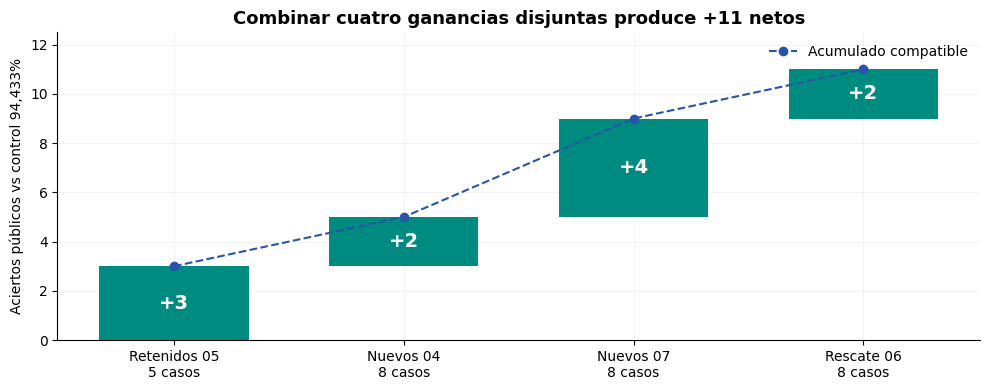

N público,Display,+06 aislado,Score combinado inferido
21000,truncate,2,0.94485
20998,round,2,0.94485


In [21]:
ganancias=np.array([3,2,4,2])
etiquetas=["Retenidos 05\n5 casos","Nuevos 04\n8 casos","Nuevos 07\n8 casos","Rescate 06\n8 casos"]
inferior=np.r_[0,np.cumsum(ganancias)[:-1]]
fig,ax=plt.subplots(figsize=(10,4))
ax.bar(etiquetas,ganancias,bottom=inferior,color=PALETA["verde"],width=.65)
for j,(d,bot) in enumerate(zip(ganancias,inferior)):
    ax.text(j,bot+d/2,f"+{d}",ha="center",va="center",color="white",weight="bold",fontsize=14)
ax.plot(np.arange(4),np.cumsum(ganancias),"o--",color=PALETA["azul"],label="Acumulado compatible")
ax.set(title="Combinar cuatro ganancias disjuntas produce +11 netos",ylabel="Aciertos públicos vs control 94,433%",ylim=(0,12.5))
ax.legend()
fig.tight_layout();plt.show()

inferidos=[]
for N,modo in [(21000,"truncate"),(20998,"round")]:
    c07=int(score_count_candidates(fila("submission_07_extiende_estable_8.csv").public_score,N,modo)[0])
    ganancia06=neto("submission_06_rescata_consenso_8.csv",N,modo)-neto("submission_03_probe_red_discrepa_10.csv",N,modo)
    nuevo=displayed_score(c07+ganancia06,N,modo)
    inferidos.append((N,modo,ganancia06,nuevo))
tabla(pd.DataFrame(inferidos,columns=["N público","Display","+06 aislado","Score combinado inferido"]),
      formatter={"Score combinado inferido":lambda v:f"{v:.5f}"})
assert all(np.isclose(r[-1],.94485) for r in inferidos)
idea("0,94485 es una inferencia de un archivo combinado que aún no se puntuó. El mejor score realmente observado sigue siendo 0,94476.")

## 8. Por qué los solapamientos se analizan juntos

Si una prueba cambia A y B, y otra cambia B y C, sus resultados comparten la contribución de B. Multiplicar dos likelihoods independientes contaría esa parte dos veces.

Agrupamos filas con el mismo patrón de participación en pruebas en **átomos**. Cada átomo tiene una ganancia pública neta latente $z_g$.

Con todos los scores:
$$
A\mathbf z=\mathbf d,\qquad -n_g\leq z_g\leq n_g,\qquad z_g\in\mathbb Z.
$$

A indica en qué pruebas aparece cada átomo, $n_g$ es su tamaño y d contiene las ganancias observadas. Las etiquetas previamente verificadas restringen además la dirección posible.

En este corte: **22 contrastes no triviales, 21 ecuaciones independientes y 25 átomos**. Un resultado redundante puede corroborar una identidad, pero no añade una ecuación independiente.

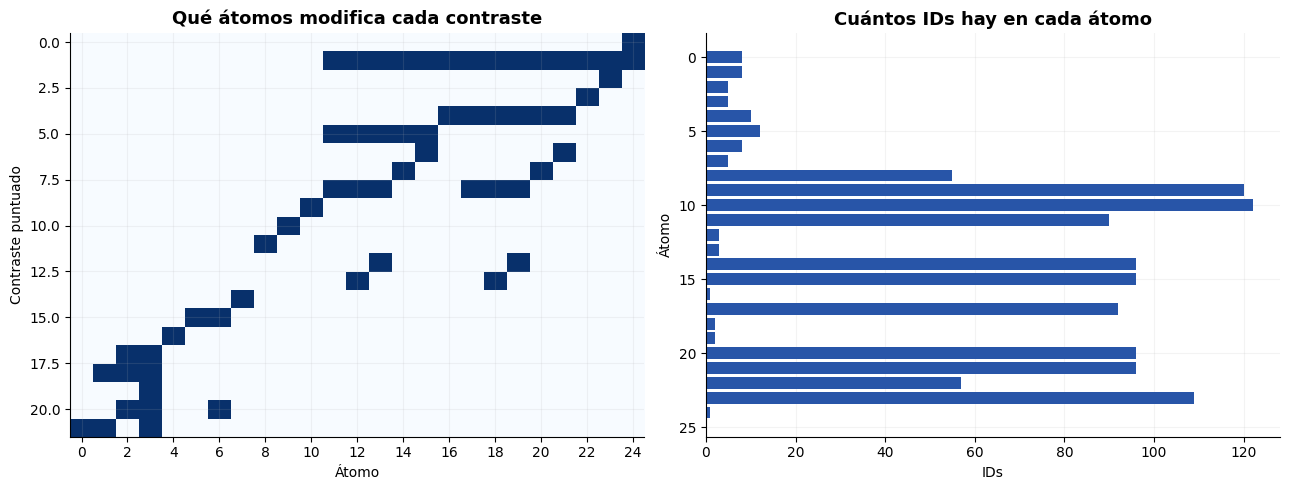

**Dimensiones comprobadas:** A = (22, 25); rango = 21.

In [22]:
sistema=D["joint_system"]
A=np.array(sistema["patterns"],int)
ds=np.array(sistema["delta"],int)
ng=np.array(sistema["atom_counts"],int)
assert A.shape==(22,25) and np.linalg.matrix_rank(A)==21
fig,axes=plt.subplots(1,2,figsize=(13,5))
axes[0].imshow(A,aspect="auto",cmap="Blues",interpolation="nearest")
axes[0].set(title="Qué átomos modifica cada contraste",xlabel="Átomo",ylabel="Contraste puntuado")
axes[0].set_xticks(np.arange(25)[::2])
axes[1].barh(np.arange(25),ng,color=PALETA["azul"])
axes[1].invert_yaxis();axes[1].set(title="Cuántos IDs hay en cada átomo",xlabel="IDs",ylabel="Átomo")
fig.tight_layout();plt.show()
display(Markdown(f"**Dimensiones comprobadas:** A = {A.shape}; rango = {np.linalg.matrix_rank(A)}."))

In [23]:
atomos=pd.DataFrame(D["joint_atoms"])
selección=atomos[(atomos.rows<=12)&(atomos.known_alternative_label<0)].head(6)
límites=[]
for row in selección.itertuples():
    lo,hi=joint_integer_bound(sistema,int(row.atom))
    assert lo==row.forced_public_net_min and hi==row.forced_public_net_max
    límites.append((int(row.atom),int(row.rows),lo,hi,lo==hi))
tabla(pd.DataFrame(límites,columns=["Átomo","Filas","D mínimo compatible","D máximo compatible","D identificado"]))
idea("Estos límites salen de las ecuaciones enteras, sin prior Beta. Identificar la suma de un átomo no equivale a identificar todas sus etiquetas.")

Átomo,Filas,D mínimo compatible,D máximo compatible,D identificado
0,8,4,4,True
1,8,2,2,True
2,5,0,0,True
3,5,3,3,True
4,10,-3,-3,True
5,12,-2,-2,True


### De las sumas a un ajuste del modelo

El análisis conjunto produce una media posterior por átomo $\boldsymbol\mu$ y una matriz de covarianza $\Sigma$.

Una forma de incorporar esa evidencia al entrenamiento es penalizar los promedios de predicciones que resultan incompatibles con ella:

$$
\mathcal L=
\sum_{\text{entrenamiento}}\mathrm{BCE}(y_i,p_i)
+\lambda\|\beta\|^2
+\frac{\eta}{2}
(\mathbf q(\beta)-\boldsymbol\mu)^\top
\Sigma_{\mathrm{reg}}^{-1}
(\mathbf q(\beta)-\boldsymbol\mu).
$$

- El primer término aprende de etiquetas reales de entrenamiento.
- El segundo limita la complejidad del corrector.
- El tercero usa **evidencia de grupo**, preservando su dependencia.
- $\mathbf q$ contiene promedios de probabilidad de la alternativa, no etiquetas asignadas al test.
- Se regulariza la covarianza para evitar una precisión numérica artificial.

También probamos una likelihood exacta para cohortes pequeñas. Toda variante debe demostrar utilidad en desarrollo antes de promoverla.

### Cuatro cosas distintas que solemos llamar «confianza»

| Cantidad | Qué afirma | Qué necesita |
|---|---|---|
| Score probabilístico del modelo | Ordena o puntúa una alternativa | Comprobar calibración si se interpreta como probabilidad |
| Límite entero de una cohorte | Qué ganancias son compatibles con todos los scores | Modelo de display y archivos correctos |
| Posterior bayesiano de cohorte | Distribución de tasas y configuraciones compatibles | Prior, máscara pública y comparabilidad |
| Proxy de máxima entropía | Reajusta creencias para concordar con sumas | Es una aproximación; no es un posterior exacto |

El motor escalable dejó verificada la factibilidad entera de las ecuaciones. El ajuste de máxima entropía tuvo un residuo máximo de aproximadamente 0,00014 aciertos en sus restricciones de media. Ese residuo pequeño no convierte sus probabilidades por fila en etiquetas verificadas.

## 9. Elegir el siguiente lote: rendimiento e información

Una ganancia esperada general se escribe:

$$
E[D_B\mid\mathcal E]=
\sum_{i\in B}\{P(Z_i=+1\mid\mathcal E)-P(Z_i=-1\mid\mathcal E)\}.
$$

Para casos nuevos de una población comparable con tasa $\theta$ y pertenencia pública independiente con probabilidad $\pi$:

$$E[D_B\mid\mathcal E]=|B|\pi\{2E[\theta\mid\mathcal E]-1\}.$$

También interesa cuánto aprenderemos del resultado. Si el score permite recuperar D y el contraste es determinista, la entropía predictiva:

$$H(D_B)=-\sum_d P(D_B=d\mid\mathcal E)\log_2 P(D_B=d\mid\mathcal E)$$

mide información sobre el estado latente conjunto. **No significa ese mismo número de bits sobre cada fila.**

Una decisión puede equilibrar ganancia esperada, información y cobertura. El peso de cada objetivo cambia cuando quedan muchas pruebas, cuando una cohorte es poco conocida o cuando se acerca el cierre.

### De qué grupos transferimos la evidencia hoy

Para una sensibilidad simple consideramos una población común para tres lotes **disjuntos** del patrón ganador:

- Diez casos de 03 con D = +3.
- Ocho nuevos de 04 con D = +2.
- Ocho nuevos de 07 con D = +4.

La comparabilidad entre esos lotes y los casos futuros es un supuesto que estamos poniendo a prueba. No se extiende automáticamente a los 2.531 casos dudosos.

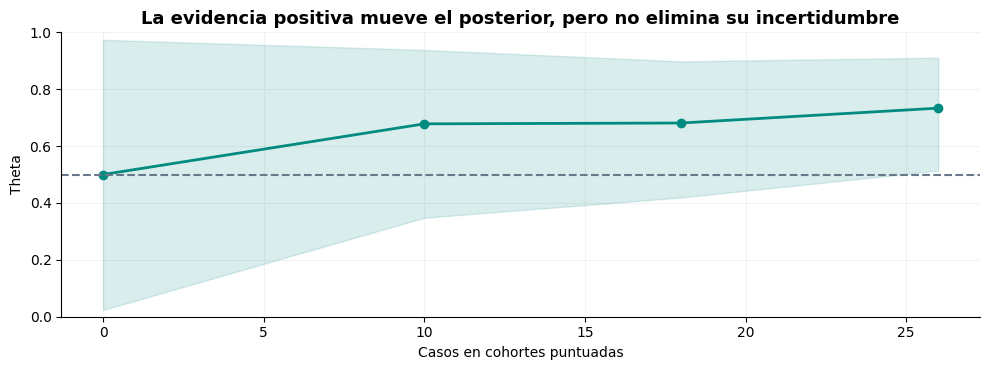

Casos observados,Media theta,Inferior95,Superior95
0,50.0%,2.4%,97.4%
10,67.8%,34.8%,93.8%
18,68.1%,41.9%,89.8%
26,73.3%,51.4%,91.1%


In [24]:
cohortes_ganadoras=[(10,3),(8,2),(8,4)]
theta,w=shared_population_grid(cohortes_ganadoras,pi=.7,a=1,b=1)
evolución=[]
for j,cohortes in enumerate([[],cohortes_ganadoras[:1],cohortes_ganadoras[:2],cohortes_ganadoras]):
    th,ww=shared_population_grid(cohortes,pi=.7,a=1,b=1)
    ci=np.interp([.025,.975],np.cumsum(ww),th)
    evolución.append((sum(n for n,d in cohortes),float(th@ww),ci[0],ci[1]))
evolución=pd.DataFrame(evolución,columns=["Casos observados","Media theta","Inferior95","Superior95"])
fig,ax=plt.subplots(figsize=(10,3.8))
ax.plot(evolución["Casos observados"],evolución["Media theta"],"o-",color=PALETA["verde"],lw=2)
ax.fill_between(evolución["Casos observados"],evolución.Inferior95,evolución.Superior95,color=PALETA["verde"],alpha=.15)
ax.axhline(.5,color=PALETA["gris"],ls="--")
ax.set(xlabel="Casos en cohortes puntuadas",ylabel="Theta",ylim=(0,1),
       title="La evidencia positiva mueve el posterior, pero no elimina su incertidumbre")
fig.tight_layout();plt.show()
tabla(evolución,formatter={"Media theta":"{:.1%}","Inferior95":"{:.1%}","Superior95":"{:.1%}"})

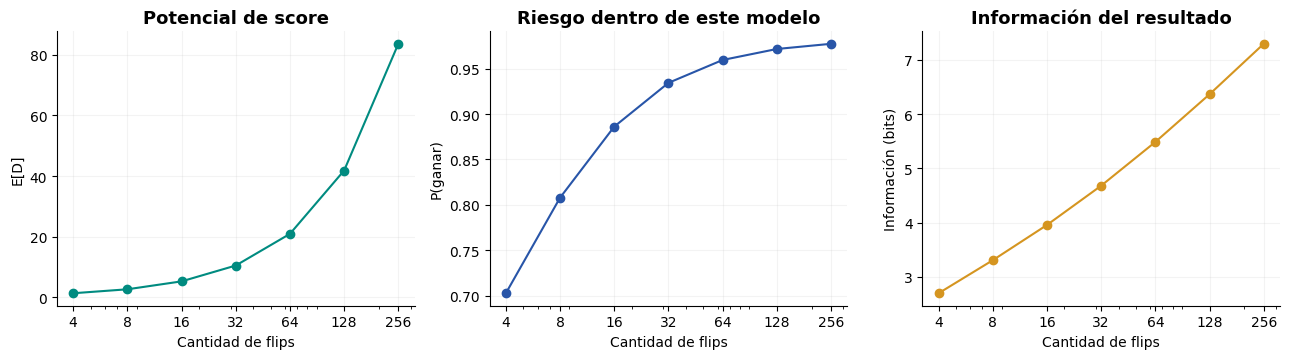

Flips,E[D],P(ganar),P(empatar),Información (bits),Intervalo predictivo 95%
4,1.3,70.3%,15.8%,2.69,"[-2, 4]"
8,2.6,80.8%,8.4%,3.30,"[-2, 7]"
16,5.2,88.6%,3.9%,3.95,"[-3, 12]"
32,10.5,93.4%,1.6%,4.68,"[-3, 22]"
64,20.9,96.0%,0.6%,5.49,"[-2, 40]"
128,41.8,97.2%,0.3%,6.37,"[-1, 78]"
256,83.7,97.7%,0.1%,7.30,"[2, 152]"


In [25]:
tamaños=[4,8,16,32,64,128,256]
predictivas=[predictive_net(n,theta,w,.7) for n in tamaños]
resumen=pd.DataFrame([{
    "Flips":p["n"],"E[D]":p["mean_net"],"P(ganar)":p["probability_gain"],
    "P(empatar)":p["probability_tie"],"Información (bits)":p["outcome_entropy_bits"],
    "Intervalo predictivo 95%":str(p["interval95"]),
} for p in predictivas])
fig,axes=plt.subplots(1,3,figsize=(13,3.7))
for ax,col,color in zip(axes,["E[D]","P(ganar)","Información (bits)"],
                        [PALETA["verde"],PALETA["azul"],PALETA["ambar"]]):
    ax.plot(resumen.Flips,resumen[col],"o-",color=color)
    ax.set(xscale="log",xlabel="Cantidad de flips",ylabel=col)
    ax.set_xticks(tamaños,[str(x) for x in tamaños])
axes[0].set_title("Potencial de score")
axes[1].set_title("Riesgo dentro de este modelo")
axes[2].set_title("Información del resultado")
fig.tight_layout();plt.show()
tabla(resumen,formatter={"E[D]":"{:.1f}","P(ganar)":"{:.1%}","P(empatar)":"{:.1%}","Información (bits)":"{:.2f}"})
idea("Estos son cálculos condicionados a compartir población. Un lote mayor no corrige por sí mismo una hipótesis de transferencia equivocada.")

### Cómo calculamos la distribución de D

Para una fila nueva de probabilidad de acierto alternativo q:

$$P(Z=-1)=\pi(1-q),\quad P(Z=0)=1-\pi,\quad P(Z=+1)=\pi q.$$

La suma de varias filas se obtiene por convoluciones. Después integramos sobre la incertidumbre posterior de theta. Esto genera tanto la ganancia esperada como el riesgo de caída, los intervalos predictivos y la entropía.

Si todas las filas comparten una theta incierta, no tratamos sus aciertos como marginalmente independientes: el promedio de distribuciones conserva esa incertidumbre común.

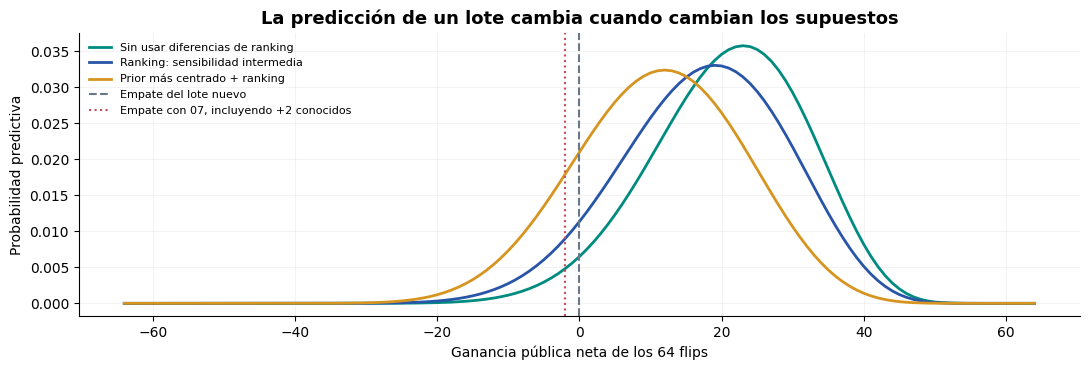

rank_temperature,prior_beta,expected_public_net_new64,central95_public_net,probability_gain_vs_best_observed_including_known_plus2
0.000000,"[1.0, 1.0]",20.9,"[-2, 40]",97.2%
0.500000,"[1.0, 1.0]",17.4,"[-7, 39]",93.9%
1.000000,"[1.0, 1.0]",13.9,"[-11, 37]",88.7%
0.000000,"[2.0, 2.0]",18.7,"[-4, 38]",96.3%
0.500000,"[2.0, 2.0]",15.0,"[-8, 36]",91.9%
1.000000,"[2.0, 2.0]",11.2,"[-13, 34]",85.2%


In [26]:
p64=predictivas[tamaños.index(64)]
assert np.isclose(p64["mean_net"],D["predictive_sensitivity"][0]["expected_public_net_new64"],atol=1e-6)
fig,ax=plt.subplots(figsize=(11,3.8))
for key,label,color in [
    ("beta1_1_temp0","Sin usar diferencias de ranking",PALETA["verde"]),
    ("beta1_1_temp0.5","Ranking: sensibilidad intermedia",PALETA["azul"]),
    ("beta2_2_temp1","Prior más centrado + ranking",PALETA["ambar"]),
]:
    ds64=np.array(D["predictive_laws"]["deltas"])
    law=np.array(D["predictive_laws"][key])
    ax.plot(ds64,law,label=label,color=color,lw=2)
ax.axvline(0,color=PALETA["gris"],ls="--",label="Empate del lote nuevo")
ax.axvline(-2,color=PALETA["rojo"],ls=":",label="Empate con 07, incluyendo +2 conocidos")
ax.set(xlabel="Ganancia pública neta de los 64 flips",ylabel="Probabilidad predictiva",
       title="La predicción de un lote cambia cuando cambian los supuestos")
ax.legend(fontsize=8)
fig.tight_layout();plt.show()
sensibilidad=pd.DataFrame(D["predictive_sensitivity"])
tabla(sensibilidad[["rank_temperature","prior_beta","expected_public_net_new64",
    "central95_public_net","probability_gain_vs_best_observed_including_known_plus2"]],
    formatter={"expected_public_net_new64":"{:.1f}","probability_gain_vs_best_observed_including_known_plus2":"{:.1%}"})

## 10. La submission de 64: qué hicimos y qué aprenderemos

**Punto de partida:** el mejor archivo observado, 07, con score público 0,94476.

**Cambio ya respaldado:** incorporar los ocho flips de 06 que aportan +2 públicos. El control combinado tiene score inferido 0,94485.

**Pregunta nueva:** qué pasa al añadir 64 casos del patrón ganador, en cuatro bloques de 16.

Para ordenarlos usamos el score heurístico:

$$
r_i=0,50\,p_{\mathrm{ref},i}
+0,20\,\widetilde p_{\mathrm{semillas},i}
+0,15\,p_{\mathrm{compacto},i}
+0,15\,p_{\mathrm{red+base},i}
-0,10\,\sigma_{\mathrm{semillas},i}.
$$

Las p están expresadas en la dirección de la alternativa. **r es un ranking, no una probabilidad calibrada.** La pareja de red sin evidencia pública aporta la referencia para las sensibilidades de transferencia; la red con evidencia también contribuye al ordenamiento.

La nueva submission tiene **72 cambios frente a 07**: ocho recuperados y 64 nuevos. Mantiene las tres etiquetas verificadas.

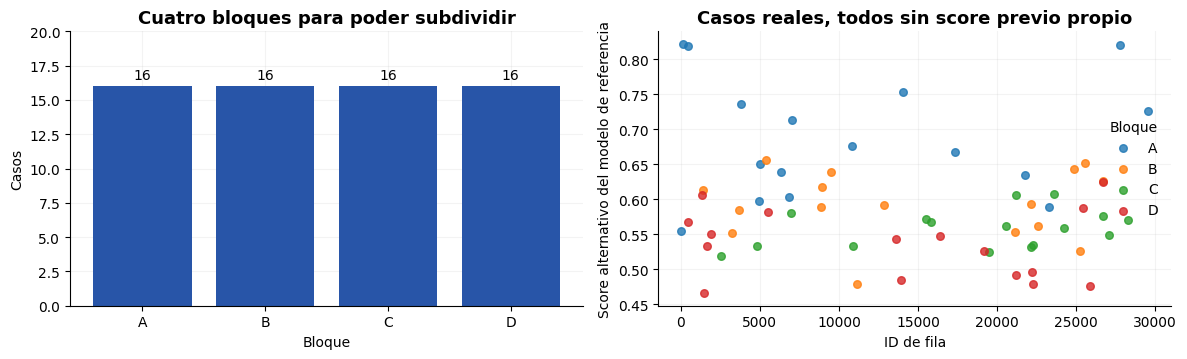

batch_block,casos,score_referencia_medio,votos_medios,ranking_medio
A,16,0.688,6.50,0.631
B,16,0.592,6.44,0.584
C,16,0.558,6.44,0.560
D,16,0.535,6.25,0.536


In [27]:
grupos=hoy.groupby("batch_block").agg(
    casos=("ID","size"),
    score_referencia_medio=("old_reference_probability_alternative","mean"),
    votos_medios=("full70k_seed_votes_alternative_out_of_7","mean"),
    ranking_medio=("ranking_final_NOT_probability","mean"),
).reset_index()
fig,axes=plt.subplots(1,2,figsize=(12,3.7))
axes[0].bar(grupos.batch_block,grupos.casos,color=PALETA["azul"])
axes[0].set(title="Cuatro bloques para poder subdividir",xlabel="Bloque",ylabel="Casos",ylim=(0,20))
for j in range(4):axes[0].text(j,16.5,"16",ha="center")
for bloque,g in hoy.groupby("batch_block"):
    axes[1].scatter(g.ID,g.old_reference_probability_alternative,label=bloque,s=30,alpha=.8)
axes[1].set(title="Casos reales, todos sin score previo propio",xlabel="ID de fila",ylabel="Score alternativo del modelo de referencia")
axes[1].legend(title="Bloque")
fig.tight_layout();plt.show()
tabla(grupos,formatter={"score_referencia_medio":"{:.3f}","votos_medios":"{:.2f}","ranking_medio":"{:.3f}"})

### Cómo leeremos el próximo score

Si $c_{07}$ es el número de aciertos compatible con el score de 07 y $c_{10}$ el de la nueva submission:

$$D_{64}=c_{10}-c_{07}-2.$$

Restamos los dos aciertos ya explicados por la incorporación de 06. Así aislamos la pregunta nueva.

El siguiente ejemplo usa resultados **hipotéticos**. No son scores recibidos de la submission 10.

In [28]:
c07=int(score_count_candidates(fila("submission_07_extiende_estable_8.csv").public_score,21000,"truncate")[0])
escenarios=[]
for d64 in [-16,-4,-2,0,8,16,24]:
    c10=c07+2+d64
    sc=displayed_score(c10,21000,"truncate")
    recovered=int(score_count_candidates(sc,21000,"truncate")[0])-c07-2
    assert recovered==d64
    escenarios.append((f"{sc:.5f}",d64,d64+2))
tabla(pd.DataFrame(escenarios,columns=["Score hipotético de 10","D de los 64","Ganancia total vs 07"]))
idea("El archivo 10 sigue pendiente en este snapshot. Un resultado negativo también será útil para decidir qué bloques separar y para revisar la transferencia.")

Score hipotético de 10,D de los 64,Ganancia total vs 07
0.94409,-16,-14
0.94466,-4,-2
0.94476,-2,0
0.94485,0,2
0.94523,8,10
0.94561,16,18
0.94600,24,26


## 11. Pasar a 75 pruebas: cubrir y después distinguir

La estrategia inicial cubre los **2.531 casos** y los divide en **32 cohortes**. Los lotes posteriores a hoy suelen ser de aproximadamente 150–270 flips. Los grupos pequeños se reservan para ambigüedades donde valga la pena afinar.

| Tramo | Pruebas | Propósito |
|---|---:|---|
| 1–20 | 20 | Cobertura amplia y caracterización |
| 21–50 | 30 | Cruces codificados y contraste de patrones |
| 51–65 | 15 | Refinamiento según incertidumbre e impacto |
| 66–75 | 10 | Confirmación y consolidación |

Es un **diseño adaptable**: sólo la prueba de hoy está convertida en un CSV para subir. Después de cada score se recalculan prioridades, contenidos y tamaño. Los efectos conocidos de cambiar el control se registran como contrastes con un ancla común.

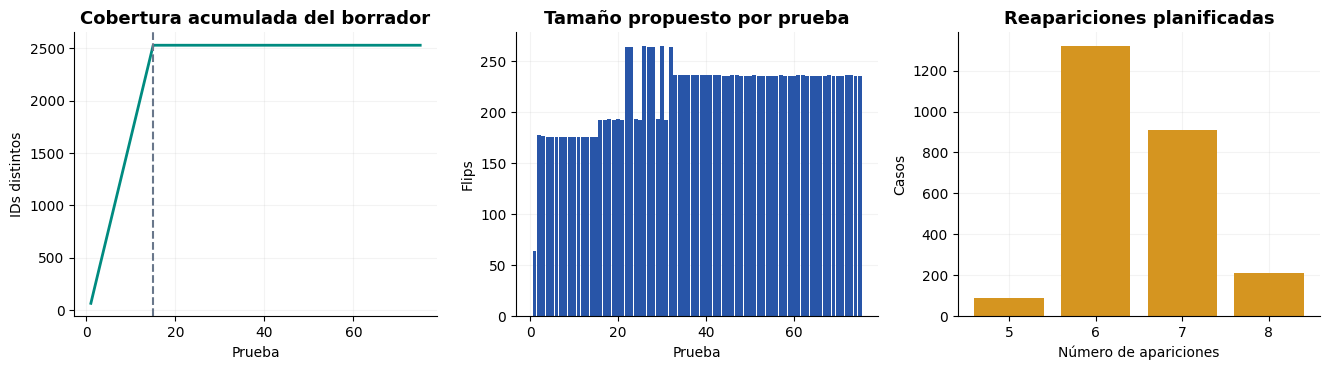

In [29]:
ids_plan=np.array(D["plan_cases"]["ids"])
cohort_id=np.array(D["plan_cases"]["cohort_ids"])
M=np.zeros((75,len(ids_plan)),dtype=np.uint8)
for j,idx in enumerate(D["plan_membership_local_indices"]):M[j,idx]=1
cobertura=np.logical_or.accumulate(M,axis=0).sum(axis=1)
exposiciones=M.sum(axis=0)
assert cobertura[14]==len(ids_plan) and len(ids_plan)==2531
assert np.linalg.matrix_rank(M.astype(float))==75
fig,axes=plt.subplots(1,3,figsize=(13.4,3.8))
axes[0].plot(np.arange(1,76),cobertura,color=PALETA["verde"],lw=2)
axes[0].axvline(15,color=PALETA["gris"],ls="--")
axes[0].set(title="Cobertura acumulada del borrador",xlabel="Prueba",ylabel="IDs distintos")
axes[1].bar(np.arange(1,76),M.sum(axis=1),color=PALETA["azul"],width=.9)
axes[1].set(title="Tamaño propuesto por prueba",xlabel="Prueba",ylabel="Flips")
v=pd.Series(exposiciones).value_counts().sort_index()
axes[2].bar(v.index,v.values,color=PALETA["ambar"])
axes[2].set(title="Reapariciones planificadas",xlabel="Número de apariciones",ylabel="Casos",xticks=v.index)
fig.tight_layout();plt.show()
idea(f"En el borrador todos los casos aparecen para la prueba 15. Cada uno participa entre {exposiciones.min()} y {exposiciones.max()} veces. Las reapariciones se analizan con su solapamiento, no como muestras independientes.")

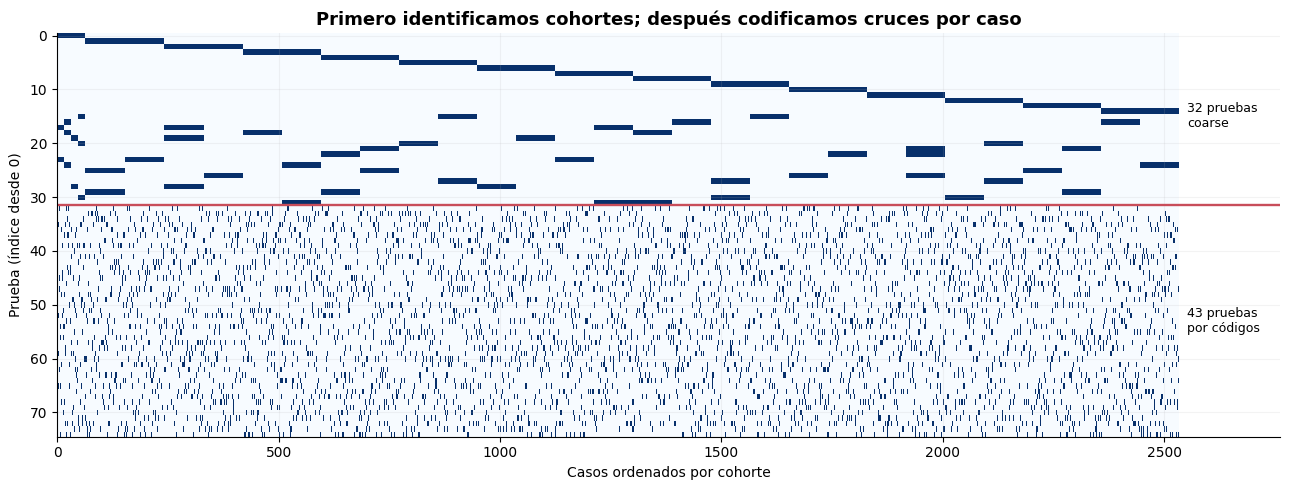

Propiedad,Valor
Cohortes iniciales,32
Casos dudosos sin verificación,2531
Firmas distintas de participación,2531
Rango total de la matriz,75
Escenarios simulados para verificar el diseño,200


In [30]:
orden=np.argsort(cohort_id,kind="stable")
fig,ax=plt.subplots(figsize=(13,5))
ax.imshow(M[:,orden],aspect="auto",interpolation="nearest",cmap="Blues")
ax.axhline(31.5,color=PALETA["rojo"],lw=1.7)
ax.set(title="Primero identificamos cohortes; después codificamos cruces por caso",
       xlabel="Casos ordenados por cohorte",ylabel="Prueba (índice desde 0)")
ax.text(len(ids_plan)+20,15,"32 pruebas\ncoarse",va="center",fontsize=9)
ax.text(len(ids_plan)+20,53,"43 pruebas\npor códigos",va="center",fontsize=9)
ax.set_xlim(-.5,len(ids_plan)+230)
fig.tight_layout();plt.show()
tabla(pd.DataFrame([
    ("Cohortes iniciales",32),
    ("Casos dudosos sin verificación",len(ids_plan)),
    ("Firmas distintas de participación",len(np.unique(M.T,axis=0))),
    ("Rango total de la matriz",np.linalg.matrix_rank(M.astype(float))),
    ("Escenarios simulados para verificar el diseño",D["plan_verification"]["simulation_scenarios"]),
],columns=["Propiedad","Valor"]))

### Tener un código por caso no alcanza para identificar todos los casos

Hay 2.531 incógnitas individuales y 75 resultados escalares. El diseño genera restricciones útiles, pero la confianza por fila también necesita modelos y supuestos de estructura.

Sí podemos verificar propiedades concretas:
- Las primeras 32 mediciones identifican las 32 ganancias de cohorte.
- Las filas posteriores dan firmas distintas a los casos y permiten refinar las ambigüedades.
- Se incluye un **centinela** con una identidad comprobable: aparece cinco veces en los 43 cruces finos, mientras los demás aparecen cuatro.

Si ejecutáramos y reconciliáramos exactamente esta matriz:

$$
\sum_{\text{43 cruces finos}}D_j-
4\sum_{\text{32 cohortes}}z_g=Z_{\mathrm{centinela}}.
$$

+1 o −1 determina la dirección correcta en público; 0 indica pertenencia oculta, sin revelar la etiqueta. Al adaptar la matriz hay que volver a comprobar la identidad.

In [31]:
primeras=np.array([np.flatnonzero(cohort_id==j)[0] for j in range(32)])
B=M[:32,primeras].astype(float)
assert np.array_equal(M[:32],B[:,cohort_id])
assert np.linalg.matrix_rank(B)==32
rng=np.random.default_rng(20261018)
# Verdad artificial para probar el álgebra, nunca etiquetas del test.
z_sim=rng.choice([-1,0,1],size=(len(ids_plan),200),p=[.25,.3,.45])
scores_sim=M @ z_sim
cohortes_reales=np.array([z_sim[cohort_id==j].sum(axis=0) for j in range(32)])
cohortes_recuperadas=np.linalg.solve(B,scores_sim[:32])
assert np.allclose(cohortes_reales,cohortes_recuperadas)
centinela_id=D["plan_manifest"]["sentinel_case_ID"]
centinela=np.flatnonzero(ids_plan==centinela_id)[0]
recuperado=scores_sim[32:].sum(axis=0)-4*cohortes_recuperadas.sum(axis=0)
assert np.allclose(recuperado,z_sim[centinela])
tabla(pd.DataFrame([
    ("Recuperación de las 32 cohortes en 200 escenarios",True),
    ("Recuperación del estado público del centinela",True),
    ("Identificación de las 2.531 etiquetas reales",False),
],columns=["Afirmación comprobada","Resultado"]))
idea("La simulación verifica el diseño matemático. No es una medición de accuracy ni evidencia de etiquetas reales.")

Afirmación comprobada,Resultado
Recuperación de las 32 cohortes en 200 escenarios,True
Recuperación del estado público del centinela,True
Identificación de las 2.531 etiquetas reales,False


## 12. Qué aportó la última ronda de entrenamiento

Se probaron **13 configuraciones nuevas** y **6 refits**. Entre las variantes hay CatBoost con diferentes políticas de crecimiento y remuestreo, selección compacta de variables y redes residuales con representaciones y regularizaciones distintas.

El uso de evidencia pública se compara con una pareja de la misma configuración y semilla sin esa restricción. Los pesos del ensemble y los tratamientos se eligen en desarrollo.

En este corte ninguna familia nueva pasó el criterio de mejora estable. Conservamos la referencia global y usamos algunas predicciones como señales para ordenar casos experimentales. **Entrenar más no obliga a reemplazar un modelo que sigue funcionando mejor.**

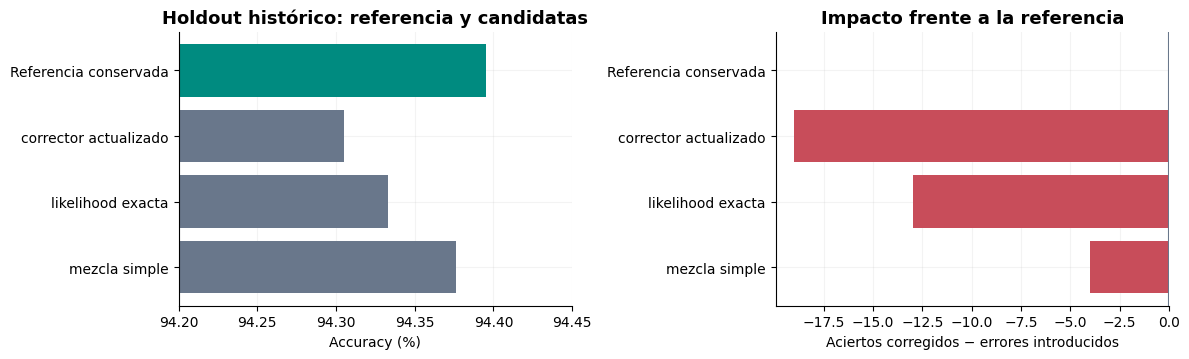

Modelo,Accuracy,Log-loss,Aciertos netos vs referencia
Referencia conservada,"94,3952%",0.145922,0
corrector actualizado,"94,3048%",0.147163,-19
likelihood exacta,"94,3333%",0.147184,-13
mezcla simple,"94,3762%",0.145945,-4


In [32]:
últimos=pd.DataFrame(D["latest_holdout"])
ref=D["reference_holdout"]
comparación=pd.DataFrame([
    {"Modelo":"Referencia conservada","Accuracy":ref["accuracy"],"Log-loss":ref["log_loss"],
     "Aciertos netos vs referencia":0},
    *[{"Modelo":r["familia"],"Accuracy":r["accuracy"],"Log-loss":r["log_loss"],
       "Aciertos netos vs referencia":int(r["net_correct"])} for _,r in últimos.iterrows()],
])
fig,axes=plt.subplots(1,2,figsize=(12,3.7))
axes[0].barh(comparación.Modelo,100*comparación.Accuracy,color=[PALETA["verde"]]+[PALETA["gris"]]*3)
axes[0].invert_yaxis();axes[0].set(xlim=(94.2,94.45),xlabel="Accuracy (%)",title="Holdout histórico: referencia y candidatas")
axes[1].barh(comparación.Modelo,comparación["Aciertos netos vs referencia"],color=[PALETA["verde"]]+[PALETA["rojo"]]*3)
axes[1].invert_yaxis();axes[1].axvline(0,color=PALETA["gris"])
axes[1].set(xlabel="Aciertos corregidos − errores introducidos",title="Impacto frente a la referencia")
fig.tight_layout();plt.show()
tabla(comparación,formatter={"Accuracy":lambda v:pct(v,4),"Log-loss":"{:.6f}"})
idea("Todas estas métricas corresponden al mismo holdout histórico. No se mezclan con el score público ni con las métricas de los refits de 70.000 filas.")

### Qué significa «mejora estable» en esta ronda

Repetimos la selección con tres particiones agrupadas de las mismas filas de desarrollo y comparamos aciertos netos frente a la referencia.

La regla de adopción requiere al menos **dos aciertos medios adicionales** y que ninguna de las tres particiones pierda más de un acierto. Se usa también el log-loss para evaluar la calidad probabilística.

Esto es un filtro práctico de estabilidad. No equivale a tres datasets independientes ni a una garantía de mejora en la evaluación oculta.

## 13. El circuito de actualización después de cada score

| Paso | Qué registramos o calculamos | Para qué sirve |
|---|---|---|
| 1. Registrar | Score exacto, archivo, hash, control e IDs | Poder reconstruir el contraste |
| 2. Decodificar | Numeradores enteros compatibles y diferencias | Separar redondeo de ganancia real |
| 3. Reconciliar | Ecuaciones conjuntas de todos los lotes | Evitar duplicar evidencia solapada |
| 4. Actualizar confianza | Límites, posterior de cohorte y proxies identificados | Reconocer lo que sabemos y lo que falta |
| 5. Elegir prueba | Ganancia, información, cobertura y presupuesto | Aprovechar cada submission |
| 6. Reentrenar | Variables, arquitecturas y correctores guiados por errores | Buscar transferencia a casos nuevos y ocultos |
| 7. Consolidar | Combinaciones de ganancias compatibles | Construir el siguiente candidato |

La finalidad es mejorar la submission completa. Una mejora pública aporta evidencia; su transferencia a la parte oculta se contrasta con validación, estabilidad y comparabilidad de los casos.

Cada score modifica el plan restante. No se interpreta cada prueba de manera aislada.

### 13.1 Actualización iterativa: corte del 20 de octubre

El relato previo conserva su corte histórico del 18 de octubre. Aquí se
incorpora un registro independiente: la submission **15 obtuvo 0,94523**.
Con la hipótesis de 21.000 filas públicas (70 % de 30.000) y truncamiento
a cinco decimales, corresponde a **19.850 aciertos públicos**. La 16 tiene
64 flips nuevos sobre la 15 y sigue pendiente. Tampoco recibimos el score
de la 14; no se le atribuye ninguna ganancia.

El objetivo es maximizar el score final de la competencia: probar flips,
buscar nuevas arquitecturas, mejorar representaciones y estudiar fuentes
adicionales del mismo dataset, conforme a las reglas aplicables.
El leaderboard agrega información sobre filas públicas: **no revela la
etiqueta individual ni demuestra transferencia al 30 % oculto**. Se
valida la transferencia por familias y folds agrupados, y se hace explícita
la incertidumbre del posterior.

Al llegar cada score: registrar el valor textual exacto en
`feedback_iterativo_20261020.json`, conservar CSV, hash, control, auditoría
de filas y patrón de cohortes, y volver a ejecutar el notebook.

In [33]:
from ap2026q2_iterative_submissions import (
    public_correct, infer_cohorts, choose_combination, validate_baseline)
from hashlib import sha256

registro_path = ROOT/'results/revision_submissions/feedback_iterativo_20261020.json'
registro = json.loads(registro_path.read_text(encoding='utf-8'))
base_path = ROOT/registro['baseline']['file']
base_15 = pd.read_csv(base_path)
validate_baseline(base_15)
assert sha256(base_path.read_bytes()).hexdigest() == registro['baseline']['sha256']

manifiesto_16 = json.loads((ROOT/'submissions/20261020/prueba_16_manifiesto.json').read_text(encoding='utf-8'))
prueba_16_path = ROOT/'submissions/20261020'/manifiesto_16['submission']
audit_path = ROOT/registro['groups_source']
assert sha256(prueba_16_path.read_bytes()).hexdigest() == manifiesto_16['submission_sha256']
assert sha256(audit_path.read_bytes()).hexdigest() == manifiesto_16['audit_sha256']
prueba_16, audit_16 = pd.read_csv(prueba_16_path), pd.read_csv(audit_path)
validate_baseline(prueba_16)
assert set(audit_16.ID) == set(base_15.loc[base_15.condition.ne(prueba_16.condition),'ID'])
assert np.array_equal(prueba_16.set_index('ID').loc[audit_16.ID,'condition'], audit_16.label_in_16)
print('15:', registro['baseline']['score'], '→', public_correct(registro['baseline']['score']),
      'aciertos públicos supuestos. Score 16:', registro['scores']['16'])

15: 0.94523 → 19850 aciertos públicos supuestos. Score 16: None


### 13.2 Grilla de cuatro pruebas nuevas que separa cohortes

Dividimos los 64 flips de la 16 en dos grupos de 32 según las siete
semillas anteriores: **A** recibe ≥4 votos para la alternativa; **B**, <4.
Los votos son un *ordenamiento*, no probabilidades calibradas. C y D
contienen 64 IDs nuevos cada una; E amplía la cobertura en 128 filas,
particionadas en cuatro subgrupos de 32. Sus CSV y auditorías se generan
con `compose_four_information_probes_20261020.py`. La matriz siguiente
describe archivos **preparados**, todavía sin scores recibidos:

| Prueba sobre la 15 | A | B | C | D | E | Ganancia pública |
|---|---:|---:|---:|---:|---:|---|
| 16 | 1 | 1 | 0 | 0 | 0 | $g_{16}=a+b$ |
| 17 | 1 | 0 | 1 | 0 | 0 | $g_{17}=a+c$ |
| 18 | 0 | 1 | 1 | 0 | 0 | $g_{18}=b+c$ |
| 19 | 0 | 1 | 0 | 1 | 0 | $g_{19}=b+d$ |
| 20 | 0 | 0 | 1 | 1 | 1 | $g_{20}=c+d+e$ |

Si se reciben los cinco resultados compatibles (16 a 20):
$a=(g_{16}+g_{17}-g_{18})/2$,
$b=(g_{16}-g_{17}+g_{18})/2$,
$c=(g_{17}+g_{18}-g_{16})/2$, $d=g_{19}-b$ y
$e=g_{20}-c-d$.
**Con un solo score, A+B es conocido pero A y B no lo son**.
Si falla paridad o el sistema no tiene solución, revisar control,
archivos, solapamientos y truncamiento antes de interpretar el resultado.

In [34]:
nombres_16 = np.where(audit_16.full70k_seed_votes_alternative_out_of_7.ge(4), 'A', 'B')
cohortes = {
    nombre: audit_16.loc[nombres_16 == nombre, ['ID','label_in_16']]
              .rename(columns={'label_in_16':'alternative_label'}).copy()
    for nombre in ('A','B')
}
assert [len(cohortes[n]) for n in ('A','B')] == [32,32]
# Incorporar CSV auditados y disjuntos con ID,alternative_label.
for nombre in ('C','D','E'):
    ruta = ROOT/f'submissions/20261020/cohorte_{nombre}_auditoria.csv'
    if ruta.exists():
        cohortes[nombre] = pd.read_csv(ruta)

if any(score is not None and not set(registro['experiments'][i]) <= set(cohortes)
       for i,score in registro['scores'].items()):
    raise ValueError('Falta auditar C/D para una submission puntuable')
activas = {'A','B'}
for i,score in registro['scores'].items():
    if score is not None:
        activas.update(registro['experiments'][i])
cohortes = {i:filas for i,filas in cohortes.items() if i in activas}
patrones = {i:grupos for i,grupos in registro['experiments'].items()
           if set(grupos) <= set(cohortes)}
resumen, posterior = infer_cohorts(
    {i:len(f) for i,f in cohortes.items()}, patrones,
    registro['scores'], registro['baseline']['score'],
    n_public=registro['assumed_public_rows'], mode=registro['public_display'])
tabla(resumen)
print('Configuraciones conjuntas compatibles:', len(posterior))

Configuraciones conjuntas compatibles: 4225


cohort,n,expected_public_gain,expected_hidden_gain,prob_public_gain_positive,feasible_public_gains,min_public_gain,max_public_gain
A,32,0.000000,-0.000000,0.484421,65,-32,32
B,32,-0.000000,-0.000000,0.484421,65,-32,32


### 13.3 De un score a una confianza y a un CSV verificable

Para cada cohorte de tamaño $n$, sean $M$ filas públicas y $K$ flips
correctos entre ellas: $g=2K-M$. El código usa
$M\sim\mathrm{Hipergeom}(30000,21000,n)$ y una previa explícita
$p\sim\mathrm{Beta}(2,2)$; el peso de cada $(M,K)$ es proporcional a
$P(M)\mathrm{BetaBinomial}(K\mid M,2,2)$.
El efecto esperado sobre las filas ocultas de la misma cohorte es
$(n-M)[2(2+K)/(4+M)-1]$. Con varias pruebas, el posterior condiciona
**simultáneamente** a todas las ecuaciones. No se asignan etiquetas
individuales a partir de una suma.

La columna `expected_hidden_gain` extrapola bajo intercambiabilidad;
para tomar decisiones se multiplica por `hidden_transfer` (por defecto
0,5). El ranking enumera combinaciones disjuntas. La consolidación
automática exige un efecto público positivo **identificado por grupo o
para la combinación exacta probada**; si gana A+B se puede conservar
entero aunque no sepamos qué aportó cada parte. Con la 16 sin score
conserva la 15. Una prueba exploratoria nueva se
diseña aparte para obtener información, según el presupuesto restante.
Repetir con previas Beta(1,1), Beta(2,2) y una previa calibrada por
CV agrupada, y factores de transferencia entre cero y uno.

In [35]:
def actualizar_submission(registro=registro, grupos=cohortes, control=base_15,
                          salida=None, hidden_transfer=.5):
    # Incorporar scores nuevos y generar opcionalmente el CSV óptimo condicional.
    matriz = {i:g for i,g in registro['experiments'].items() if set(g) <= set(grupos)}
    resumen, configuraciones = infer_cohorts(
        {i:len(f) for i,f in grupos.items()}, matriz,
        registro['scores'], registro['baseline']['score'],
        n_public=registro['assumed_public_rows'], mode=registro['public_display'])
    ranking, prediccion = choose_combination(
        resumen, configuraciones, grupos, control,
        hidden_transfer=hidden_transfer, require_observed_positive=True)
    if salida is not None:
        salida = Path(salida)
        assert salida.suffix.lower() == '.csv' and salida.parent.exists()
        prediccion.to_csv(salida, index=False)
        assert pd.read_csv(salida).equals(prediccion)
        manifiesto = {'baseline_sha256':registro['baseline']['sha256'],
                      'scores':registro['scores'], 'cohorts':ranking.iloc[0].cohorts,
                      'csv_sha256':sha256(salida.read_bytes()).hexdigest(),
                      'public_rows_hypothesis':registro['assumed_public_rows'],
                      'hidden_transfer':hidden_transfer}
        salida.with_suffix('.json').write_text(json.dumps(manifiesto,indent=2),encoding='utf-8')
    return ranking, prediccion

ranking, mejor_condicional = actualizar_submission()
tabla(ranking.head(8))
print('Flips consolidados con scores disponibles:',
      int((mejor_condicional.condition != base_15.condition).sum()))
# Tras registrar los scores, descomentar para exportar:
# ranking, csv = actualizar_submission(salida=ROOT/'submissions/20261020/submission_consolidada.csv')

Flips consolidados con scores disponibles: 0


cohorts,flips,expected_public_gain,expected_hidden_gain_discounted,prob_public_improvement
,0,0.000000,0.000000,0.000000


In [36]:
# Un caso independiente verifica que las cinco ecuaciones separan los efectos.
from itertools import product
efectos = np.array([3,-2,7,-1,5])
matriz_ejemplo = np.array([[1,1,0,0,0],[1,0,1,0,0],[0,1,1,0,0],
                           [0,1,0,1,0],[0,0,1,1,1]])
assert np.array_equal(np.linalg.solve(matriz_ejemplo, matriz_ejemplo@efectos), efectos)
assert len(audit_16) == 64 and public_correct('0.94523') == 19850
if registro['scores']['16'] is None:
    assert int(ranking.iloc[0].flips) == 0  # no inventar evidencia pendiente
print('Diseño, archivos y evidencia observada comprobados.')

Diseño, archivos y evidencia observada comprobados.


## 14. Guion breve para presentar

1. **Problema:** el modelo predice 30.000 publicaciones, pero sólo vemos un score agregado.
2. **Experimento:** cambiar un lote convierte el score en una ecuación sobre sus aciertos.
3. **Incertidumbre:** +4 en ocho flips admite varias configuraciones; Bayes las pondera.
4. **Aprendizaje real:** la división del grupo neutral encontró un subconjunto +2 y otro −2.
5. **Consolidación:** combinar 06 con 07 da 94,485% inferido; el archivo de 64 casos formula una pregunta nueva.
6. **Escala:** el plan de 75 cubre el universo y usa cruces para distinguir grupos y casos.
7. **Sinergia:** los resultados orientan modelos y datos; los modelos orientan las próximas pruebas.
8. **Cierre del corte:** mejor público observado 94,476%; la submission 10 está pendiente.

**Preguntas que podemos responder con el notebook**
- ¿Por qué un score mayor no demuestra que todos los flips del lote sean correctos?
- ¿Cuál es la diferencia entre un score del modelo y un posterior de cohorte?
- ¿Qué supuesto permite extrapolar un patrón a casos no probados?
- ¿Por qué importan el solapamiento y el rango de la matriz?
- ¿Qué resultado haría cambiar el siguiente lote?

## Fuentes y reproducibilidad

**Datos del proyecto**
- results/revision_submissions/submission_feedback_log.csv: scores registrados y notas de origen.
- snapshot_20261018.json: hashes, cambios efectivos por archivo, auditorías, conteos, restricciones y plan provisional.
- snapshot_manifest.json: integridad del snapshot y conteos de control.
- Las etiquetas del test oculto no forman parte del material.

**Referencias técnicas primarias**
- [SciPy: distribución beta-binomial](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.betabinom.html): mezcla binomial con probabilidad Beta.
- [SciPy: distribución hipergeométrica](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.hypergeom.html): muestreo sin reemplazo.
- [SciPy: programación lineal entera mixta](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.milp.html): límites compatibles con ecuaciones y variables enteras.
- [CatBoost: parámetros de entrenamiento](https://catboost.ai/docs/en/references/training-parameters/common): variantes de los modelos de la última ronda.

**Actualizar**
1. Incorporar un score al registro del entorno de experimentos.
2. Actualizar auditorías y la evidencia correspondiente.
3. Regenerar el snapshot con scripts/build_submission_review_snapshot.py.
4. Ejecutar este notebook desde cero y revisar sus comprobaciones.
5. Versionar juntos notebook, snapshot y resultados. Las fechas y scores inferidos deben conservar su etiqueta de estado.

In [37]:
# Comprobaciones finales de consistencia de esta explicación.
assert len(observadas)==C["scored_submissions"]==23
assert len(pendientes)==C["pending_submissions"]==4
assert len(casos)==2531 and len(set(ids_plan))==2531
assert len(hoy)==64 and hoy.batch_block.value_counts().eq(16).all()
assert len(s07|rescatados06)==29
assert D["submission10_manifest"]["total_changes_vs_observed07"]==72
assert D["submission10_manifest"]["known_labels_preserved"]==3
assert np.isclose(post07["finite_cohort_accuracy_mean"],.8445564020643799)
assert np.isclose(post07["theta_mean"],.7756451216515027)
assert not D["scope"]["public_N_officially_confirmed"]
display(Markdown("**Comprobaciones completadas:** registro, casos, contrastes, posterior, diseño y estado pendiente de la nueva submission son consistentes."))

**Comprobaciones completadas:** registro, casos, contrastes, posterior, diseño y estado pendiente de la nueva submission son consistentes.